Name : Mohammad Ayaan Khan

USC ID : 4147952900

Email id : mkhan736@usc.edu

# DSCI 552 — Homework 4
## Problem 1: Time Series Classification Part 1 (Feature Creation/Extraction, from Homework 3)
## Problem 2: Time Series Classification Part 2 (Binary and Multiclass Classification)
## Problems 3 and 4: ISLR 4.8.3 and 4.8.7

# Problem 1. Time Series Classification Part 1: Feature Creation/Extraction (Homework 3)



## 1. Imports and configuration

In [1]:
from pathlib import Path
from zipfile import ZipFile
import urllib.request
import shutil
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 552
rng = np.random.default_rng(RANDOM_STATE)
# ARem Dataset.
DATA = "https://archive.ics.uci.edu/static/public/366/activity+recognition+system+based+on+multisensor+data+fusion+arem.zip"
WORKDIR = Path("arem_data")
WORKDIR.mkdir(exist_ok=True)

## 2. Download and extract AReM Data

In [2]:
zip = WORKDIR / "arem.zip"
dir = WORKDIR / "extracted"
dir.mkdir(parents=True, exist_ok=True)
if not zip.exists():
    print("Downloading AReM dataset...")
    urllib.request.urlretrieve(DATA, zip)
print("Dataset ZIP exists:", zip.exists())
with ZipFile(zip, "r") as zf:
    zf.extractall(dir)
print("Dataset extracted to:",dir.resolve())
#The seven activity folders
activities = {
    "bending1", "bending2", "cycling", "lying",
    "sitting", "standing", "walking"
}
dirs = [
    p for p in dir.rglob("*")
    if p.is_dir() and p.name.lower() in activities
]
act_dirs = {p.name.lower(): p for p in dirs}
print("Activity folders found:", sorted(act_dirs.keys()))
missing = activities - set(act_dirs.keys())
if missing:
    raise FileNotFoundError(
        f"Missing activity folders: {sorted(missing)}"
    )

Dataset ZIP exists: True
Dataset extracted to: /content/arem_data/extracted
Activity folders found: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']


## 3. Cleaning the individual time-series files


In [3]:
## Each file that is on AReM should be parsed and cleaned into a DataFrame per instance, identifying all parsing errors, stopping in case less than 88 instances load, and marking a file with less than 480 valid rows.
import csv
import re
from pathlib import Path
import pandas as pd
COL = ["avg_rss12", "var_rss12", "avg_rss13",
    "var_rss13", "avg_rss23", "var_rss23"
]
def _canonical_column(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())
def read_arem_file(path):
    path = Path(path)
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    idx = None
    for i, line in enumerate(lines):
        normalized = _canonical_column(line)
        if all(_canonical_column(sensor) in normalized for sensor in COL):
            idx = i
            break
    if idx is None:
        raise ValueError("Could not find a header containing all six sensor columns")
    rows = []
    malf_rows = 0
    for line in lines[idx + 1:]:
        stripped = line.strip()
        if not stripped:
            continue
        # Accept comma-separated, tab-separated, or whitespace-separated data.
        toks = [t for t in re.split(r"[,\s]+", stripped) if t]
        try:
            val = [float(token) for token in toks[:7]]
        except ValueError:
            # Ignoring repeated headers, labels, and other nonnumeric lines.
            continue
        if len(val) == 7:
            rows.append(val)
        else:
            malf_rows += 1
    if not rows:
        raise ValueError("No valid numeric sensor rows found")
    df = pd.DataFrame(rows, columns=["time"] + COL)
    df = df[COL].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=COL, how="any").reset_index(drop=True)
    if df.empty:
        raise ValueError("No valid numeric sensor rows found after cleaning")
    return df
records = []
load_errors = []
for act, folder in sorted(act_dirs.items()):
    for path in sorted(p for p in folder.iterdir() if p.is_file() and not p.name.startswith(".")):
        try:
            series_df = read_arem_file(path)
            records.append({
                "activity": act,
                "file": path.name,
                "path": str(path),
                "data": series_df
            })
        except Exception as exc:
            load_errors.append({
                "activity": act,
                "file": path.name,
                "error": str(exc)
            })
print("Successfully loaded instances:", len(records))
print("Files with parsing errors:", len(load_errors))
if load_errors:
    display(pd.DataFrame(load_errors))
display(pd.Series([r["activity"] for r in records]).value_counts().sort_index())
# Stopping instead of calculating features from an incomplete dataset.
if len(records) != 88:
    raise RuntimeError(f"Expected 88 AReM instances but loaded {len(records)}.""Review the parsing-error table above before continuing.")
len_issues = [
    (r["activity"], r["file"], len(r["data"]))
    for r in records if len(r["data"]) != 480]
if len_issues:
    print("Files not containing exactly 480 valid sensor rows:")
    display(pd.DataFrame(len_issues, columns=["activity", "file", "valid_rows"]))
else:
    print("All instances contain 480 valid sensor rows.")

Successfully loaded instances: 88
Files with parsing errors: 0


,count
bending1,7
bending2,6
cycling,15
lying,15
sitting,15
standing,15
walking,15


Files not containing exactly 480 valid sensor rows:


,activity,file,valid_rows
0,sitting,dataset8.csv,479


## 4. Verifying the dataset and splitting the required train/test



In [4]:
def dataset_number(filename):
    match = re.search(r"dataset\s*[_-]?(\d+)", filename.lower())
    if match:
        return int(match.group(1))
    # Fallback: first integer in filename.
    match = re.search(r"(\d+)", filename)
    return int(match.group(1)) if match else None
def is_test_instance(activity, filename):
    n = dataset_number(filename)
    if activity in {"bending1", "bending2"}:
        return n in {1, 2}
    return n in {1, 2, 3}
for r in records:
    r["dataset_number"] = dataset_number(r["file"])
    r["split"] = "test" if is_test_instance(r["activity"], r["file"]) else "train"
split_summ = pd.crosstab(
    pd.Series([r["activity"] for r in records], name="activity"),
    pd.Series([r["split"] for r in records], name="split")
)
display(split_summ)
print("Total instances:", len(records))
print("Train instances:", sum(r["split"] == "train" for r in records))
print("Test instances:", sum(r["split"] == "test" for r in records))
# 88 instances total.
if len(records) != 88:
    print("WARNING: The assignment describes 88 instances. Check the archive layout, "
          "file parsing, and any skipped files before relying on results.")

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


Total instances: 88
Train instances: 69
Test instances: 19


## 5. Extracting seven time-domain features from each of six series


In [5]:
#Extract seven time-domain features (min, max, mean, median, std, Q1, Q3) for every instance across the six series of sensors to obtain a numerical feature matrix consisting of 42 columns, along with its relevant metadata.
feat = ["min", "max", "mean", "median", "std", "q1", "q3"]
def extract_features(instance):
    row = {
        "activity": instance["activity"],
        "file": instance["file"],
        "dataset_number": instance["dataset_number"],
        "split": instance["split"]
    }
    for sensor in COL:
        val = instance["data"][sensor].to_numpy(dtype=float)
        pref = sensor
        row[f"{pref}_min"] = np.min(val)
        row[f"{pref}_max"] = np.max(val)
        row[f"{pref}_mean"] = np.mean(val)
        row[f"{pref}_median"] = np.median(val)
        row[f"{pref}_std"] = np.std(val, ddof=1)
        row[f"{pref}_q1"] = np.quantile(val, 0.25)
        row[f"{pref}_q3"] = np.quantile(val, 0.75)
    return row
feature_df = pd.DataFrame([extract_features(r) for r in records])
feature_cols = [
    f"{sensor}_{feature}"
    for sensor in COL
    for feature in feat
]
display(feature_df.head())
print("Feature matrix shape (including metadata):", feature_df.shape)
print("Number of numerical features:", len(feature_cols))

,activity,file,dataset_number,split,avg_rss12_min,avg_rss12_max,avg_rss12_mean,avg_rss12_median,avg_rss12_std,avg_rss12_q1,...,avg_rss23_std,avg_rss23_q1,avg_rss23_q3,var_rss23_min,var_rss23_max,var_rss23_mean,var_rss23_median,var_rss23_std,var_rss23_q1,var_rss23_q3
0,bending1,dataset1.csv,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,dataset2.csv,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,dataset3.csv,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,dataset4.csv,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,dataset5.csv,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


Feature matrix shape (including metadata): (88, 46)
Number of numerical features: 42


In [6]:
# Rename the 42 feature columns according to required rules and re-index the table from 1.
stat_names = {
    "min": "min", "max": "max", "mean": "mean", "median": "median",
    "std": "std", "q1": "1st_quart", "q3": "3rd_quart"
}
map = {
    f"{sensor}_{stat}": f"{stat_names[stat]}{i}"
    for i, sensor in enumerate(COL, start=1)
    for stat in feat
}
table = feature_df.rename(columns=map).copy()
table.index = pd.RangeIndex(1, len(table) + 1, name="Instance")
display(table.head())
print("Assignment-style feature table shape:", table.shape)

,activity,file,dataset_number,split,min1,max1,mean1,median1,std1,1st_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,dataset1.csv,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,bending1,dataset2.csv,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,bending1,dataset3.csv,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,bending1,dataset4.csv,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,bending1,dataset5.csv,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


Assignment-style feature table shape: (88, 46)


Using the 88 cases as our observational units. For each feature, we calculate the standard deviation of values across cases. To form a 90% CI, we will use percentiles and perform a bootstrap sampling of cases with replacement and then compute the 5th and 95th percentiles of the distribution of bootstrap sampling estimates of the standard deviation.

This calculated interval gives a measure of the uncertainty in the standard deviation computed across all instances, but it does not yield an interval pertaining to a particular value of a time series.

In [7]:
def bootstrap_sd_ci(values, n_boot=5000, confidence=0.90, seed=552):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan, np.nan, np.nan
    loc_rng = np.random.default_rng(seed)
    n = len(values)
    boot_sds = np.empty(n_boot)
    for b in range(n_boot):
        sample = loc_rng.choice(values, size=n, replace=True)
        boot_sds[b] = np.std(sample, ddof=1)
    alp = 1 - confidence
    return (
        np.std(values, ddof=1),
        np.quantile(boot_sds, alp / 2),
        np.quantile(boot_sds, 1 - alp / 2)
    )
ci_rows = []
for j, col in enumerate(feature_cols):
    estimate, low, high = bootstrap_sd_ci(
        feature_df[col].to_numpy(), n_boot=5000, confidence=0.90,
        seed=RANDOM_STATE + j
    )
    ci_rows.append({
        "feature": col,
        "estimated_sd": estimate,
        "90% CI lower": low,
        "90% CI upper": high
    })
sd_ci_table = pd.DataFrame(ci_rows).sort_values("feature").reset_index(drop=True)
display(sd_ci_table.round(4))

,feature,estimated_sd,90% CI lower,90% CI upper
0,avg_rss12_max,4.3944,3.3607,5.2954
1,avg_rss12_mean,5.3357,4.6930,5.9045
2,avg_rss12_median,5.4401,4.7818,5.9909
3,avg_rss12_min,9.5700,8.2629,10.7754
4,avg_rss12_q1,6.1536,5.5620,6.6487
5,avg_rss12_q3,5.1389,4.3463,5.8195
6,avg_rss12_std,1.7722,1.5788,1.9615
7,avg_rss13_max,4.8751,4.1773,5.4748
8,avg_rss13_mean,4.0084,3.4085,4.4781
9,avg_rss13_median,4.0364,3.4579,4.5436


### Visualizing the estimated standard deviations

High standard deviations indicate features that vary a lot across instances, but variation is not enough to ensure good classification results.

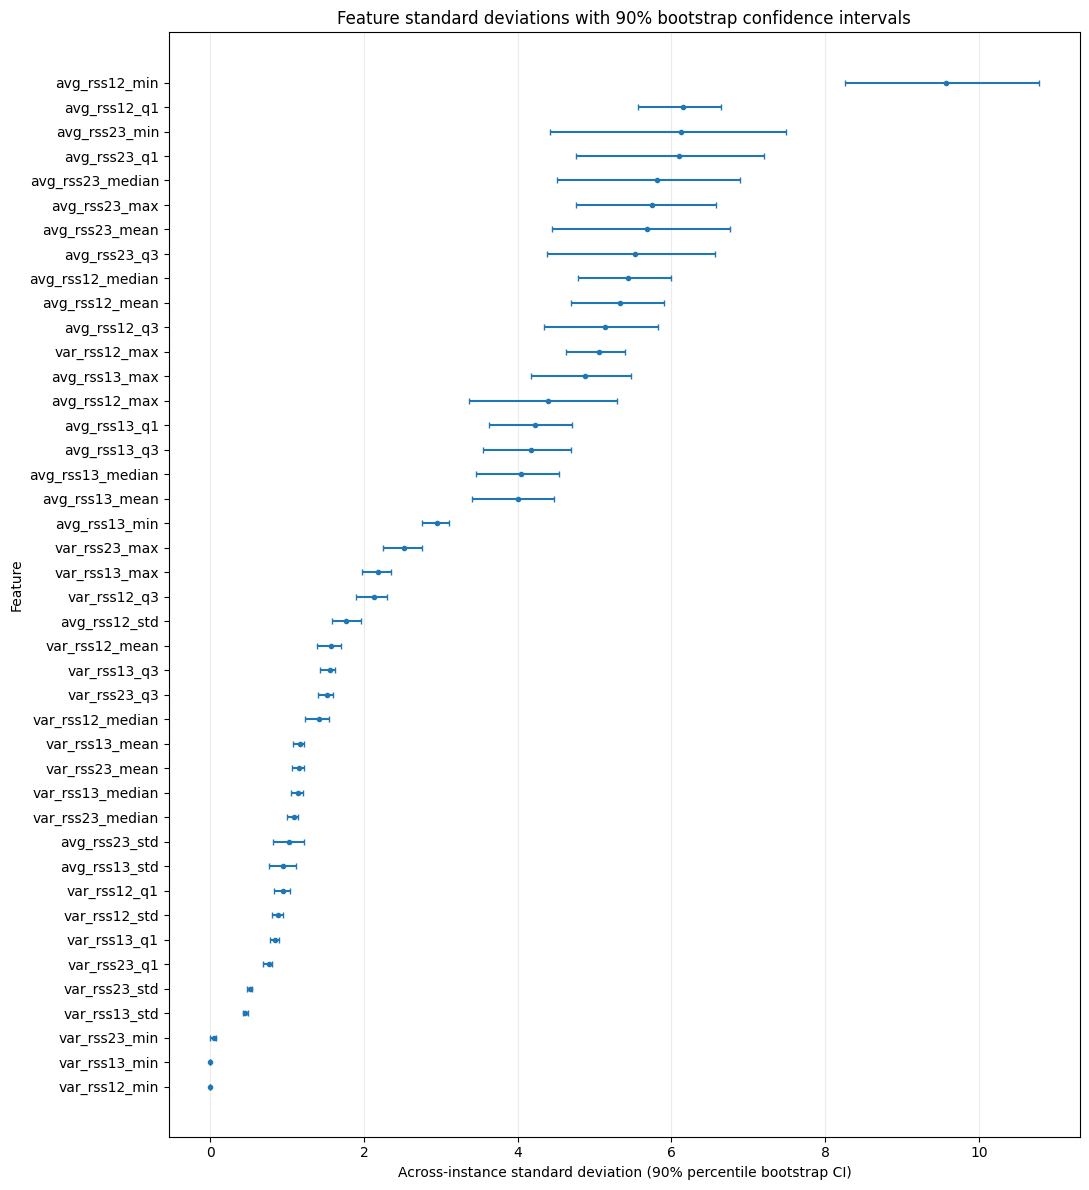

In [8]:
plot_df = sd_ci_table.sort_values("estimated_sd", ascending=True).reset_index(drop=True)
lower_err = plot_df["estimated_sd"] - plot_df["90% CI lower"]
upper_err = plot_df["90% CI upper"] - plot_df["estimated_sd"]
fig, ax = plt.subplots(figsize=(11, 12))
ax.errorbar(
    plot_df["estimated_sd"],
    plot_df["feature"],
    xerr=[lower_err, upper_err],
    fmt="o",
    capsize=2,
    markersize=3
)
ax.set_title("Feature standard deviations with 90% bootstrap confidence intervals")
ax.set_xlabel("Across-instance standard deviation (90% percentile bootstrap CI)")
ax.set_ylabel("Feature")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Selecting three important time-domain features

In our case, what is required is not choosing three particular columns that represent individual sensors, but rather opting for three general types of time-domain statistical measures. Our selection includes the following measures: minimum value, mean and maximum value. While minimum and maximum represent extremities of a signal, the mean value is indicative of the average signal level. These measures provide a means of differentiating between movements with higher fluctuations and more static positions. The median and quartiles represent central tendency as well, but they may partly overlap with the mean measure.

In order to receive supporting evidence without actually using the test set for the purpose of selecting the features, the next section is intended to rank features based exclusively on ANOVA F-statistics that are calculated for the training dataset only. The final choice of minimum, mean, and maximum remains a judgment-based choice permitted by the assignment

Median ANOVA F-statistic across the six sensor series (training set only):


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 7 21] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,median_F
stat,
mean,307.442
q3,297.070
median,252.826
q1,135.156
std,71.918
max,32.327
min,16.841


Selected statistic types: ['min', 'mean', 'max']


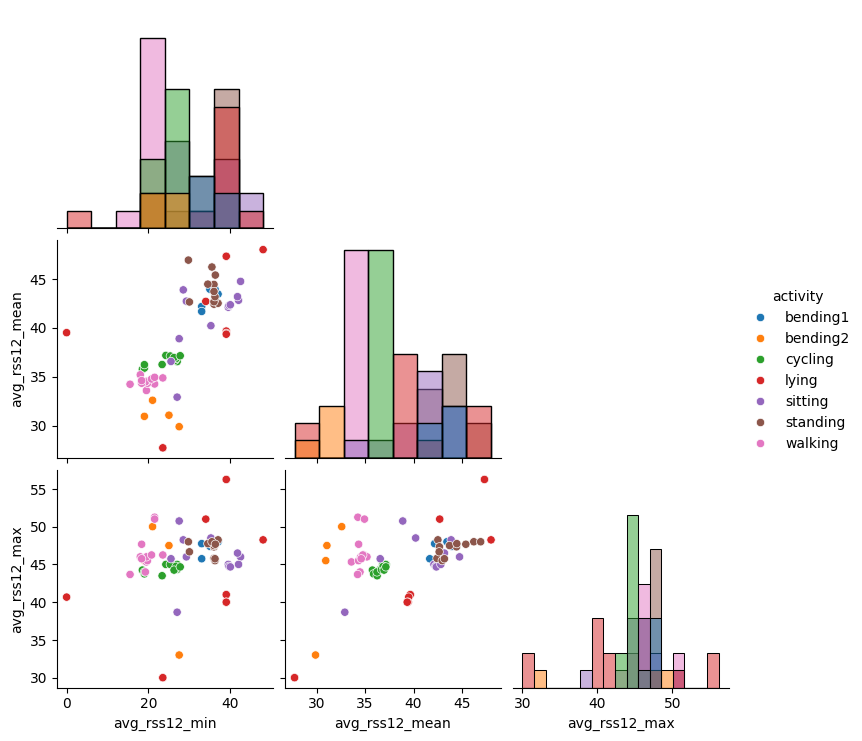

In [9]:
from sklearn.feature_selection import f_classif
train_df = feature_df.loc[feature_df["split"] == "train"].copy()
F, p_values = f_classif(train_df[feature_cols], train_df["activity"])
f_df = pd.DataFrame({"F": F, "p_value": p_values}, index=feature_cols)
f_df["stat"] = [c.rsplit("_", 1)[1] for c in feature_cols]
stat_ranking = f_df.groupby("stat")["F"].median().sort_values(ascending=False)
print("Median ANOVA F-statistic across the six sensor series (training set only):")
display(stat_ranking.to_frame("median_F").round(3))
selected_stats = ["min", "mean", "max"]
print("Selected statistic types:", selected_stats)
# Illustrative plot for sensor series 1 using the three selected statistics.
example_features = ["avg_rss12_min", "avg_rss12_mean", "avg_rss12_max"]
sns.pairplot(
    feature_df.loc[feature_df["split"] == "train"],
    vars=example_features,
    hue="activity",
    diag_kind="hist",
    corner=True)
plt.show()

## 8. Export the extracted feature table and confidence intervals

The generated files can be reused for the later classification portion of the assignment.

In [10]:
output_dir = Path("arem_outputs")
output_dir.mkdir(exist_ok=True)
feature_df.to_csv(output_dir / "arem_features_42.csv", index=False)
sd_ci_table.to_csv(output_dir / "feature_sd_bootstrap_ci_90.csv", index=False)
print("Saved:")
print(output_dir / "arem_features_42.csv")
print(output_dir / "feature_sd_bootstrap_ci_90.csv")

Saved:
arem_outputs/arem_features_42.csv
arem_outputs/feature_sd_bootstrap_ci_90.csv


## 9.1(c)

### (i) Common time-domain features

Several time-domain characteristics are utilized, such as minimum, maximum, range, mean, median, variance, standard deviation, RMS, quantiles (quartiles, IQR), and the skewness and kurtosis of a sample, as well as the zero-crossing rate and slope/trend. However, in this case, only a few of them are required in this assignment, i.e., the minimum, maximum, mean, median, standard deviation, first quartile, and third quartile.

### (ii) Extracted feature table

The program generates one row for each activity instance along with 42 numerical characteristics which are composed of 7 statistics for the 6 sensor series. The activity, the file, and the split columns constitute metadata and they are not included in the 42-feature vector.
### (iii) Standard deviations and bootstrap intervals
The sample standard deviations for every characteristic are shown in the table sd_ci_table, along with the values of the associated  percentile 90% bootstrap confidence interval. The numbers listed here were taken from the output generated from this notebook after downloading the data set and making sure its processing is correct.

Because all the instances bring their variance series down to zero at some point, the two minimum variance series (var_rss12_min, var_rss13_min) have a standard deviation of 0, along with 90% CI of [0,0]. The value of var_rss23_min is almost the same because of this.

### (iv) Three selected features

The three chosen statistics of time-domain are **minimum, mean and maximum**. Minimum and maximum demonstrate extremes of the signal while the mean indicates normal signal level. The training based ANOVA ranking gives evidence about class separation without using the testing labels in selecting the features.

Minimum has good significance in avg_rss series, however, it is (almost) always 0 in the var_rss series, meaning that in case of these series the only relevant statistics could be mean and max.

**Data note:** The original dataset has duplicate instances. For instance, cycling/dataset1 = cycling/dataset15, lying/dataset1 ≈ lying/dataset10 = lying/dataset15, lying/dataset3 = lying/dataset11. The pre-defined split is maintained; however, since 3 test instances have duplicates in the train dataset, test accuracy could be overestimated at classification stage.

# Problem 2. Time Series Classification Part 2: Binary and Multiclass Classification

## 2.0 Setup: Problem 1 features generalized to l pieces per series

Problem 2 uses features from Problem 1, however there is an addition; each of the six series may be divided into $l$ approximately equal length segments. The seven statistical measures (min, max, mean, median, standard deviation, Q1, Q3) are then calculated for each segment. Therefore, if there are $l$ segments, the instance will contain $6 \times 7 \times l = 42l$ features. The total number of instances (88) remains constant.

The train/test split is what is required in 1(b). Datasets 1 and 2 from bending1 and bending2 as well as datasets 1, 2, and 3 from each other folder will make up the test data (19 instances), while the remaining 69 will be used for training purposes..

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import urllib.request, re, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_curve, roc_auc_score,
                             auc, ConfusionMatrixDisplay, log_loss)
warnings.filterwarnings("ignore")# convergence / separation warnings are discussed in the text instead
RANDOM_STATE = 552
np.random.seed(RANDOM_STATE)
# Colors: fixed categorical order (blue, orange, aqua, yellow, magenta, green, violet)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
BIN_COLORS = {"other": PALETTE[0], "bending": PALETTE[1]}
sns.set_theme(style="whitegrid", context="notebook")
print("scikit-learn", sklearn.__version__, "| statsmodels", sm.__version__)

scikit-learn 1.6.1 | statsmodels 0.15.0


In [12]:
DATA = "https://archive.ics.uci.edu/static/public/366/activity+recognition+system+based+on+multisensor+data+fusion+arem.zip"
WORKDIR = Path("arem_data"); WORKDIR.mkdir(exist_ok=True)
zip_path, ext_dir = WORKDIR / "arem.zip", WORKDIR / "extracted"
if not zip_path.exists():
    urllib.request.urlretrieve(DATA, zip_path)
with ZipFile(zip_path) as zf:
    zf.extractall(ext_dir)

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
act_dirs = {p.name.lower(): p for p in ext_dir.rglob("*") if p.is_dir() and p.name.lower() in ACTIVITIES}
assert set(act_dirs) == set(ACTIVITIES), act_dirs.keys()
COL = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
STATS = ["min", "max", "mean", "median", "std", "q1", "q3"]
def _canon(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())
def read_arem_file(path):
    # Same cleaning as HW3: find the header, accept comma/space/tab separated rows, skip junk lines.
    lines = Path(path).read_text(encoding="utf-8", errors="replace").splitlines()
    idx = next(i for i, ln in enumerate(lines) if all(_canon(c) in _canon(ln) for c in COL))
    rows = []
    for ln in lines[idx + 1:]:
        toks = [t for t in re.split(r"[,\s]+", ln.strip()) if t]
        try:
            vals = [float(t) for t in toks[:7]]
        except ValueError:
            continue
        if len(vals) == 7:
            rows.append(vals)
    return pd.DataFrame(rows, columns=["time"] + COL)[COL]

def dataset_number(name):
    return int(re.search(r"(\d+)", name).group(1))
records = []
for act in ACTIVITIES:
    for p in sorted(act_dirs[act].glob("*.csv"), key=lambda q: dataset_number(q.name)):
        n = dataset_number(p.name)
        is_test = n in ({1, 2} if act.startswith("bending") else {1, 2, 3})
        records.append({"activity": act, "file": p.name, "split": "test" if is_test else "train",
                        "data": read_arem_file(p)})
meta = pd.DataFrame({k: [r[k] for r in records] for k in ["activity", "file", "split"]})
assert len(records) == 88
print(pd.crosstab(meta["activity"], meta["split"]))
# Exact duplicate recordings (relevant when interpreting test accuracy)
groups = {}
for r in records:
    groups.setdefault(r["data"].round(4).to_numpy().tobytes(), []).append(f'{r["activity"]}/{r["file"]} ({r["split"]})')
print("\nIdentical recordings:")
for g in groups.values():
    if len(g) > 1:
        print("  " + "  ==  ".join(g))

split     test  train
activity             
bending1     2      5
bending2     2      4
cycling      3     12
lying        3     12
sitting      3     12
standing     3     12
walking      3     12

Identical recordings:
  cycling/dataset1.csv (test)  ==  cycling/dataset15.csv (train)
  lying/dataset1.csv (test)  ==  lying/dataset15.csv (train)
  lying/dataset3.csv (test)  ==  lying/dataset11.csv (train)
  lying/dataset5.csv (train)  ==  lying/dataset12.csv (train)
  lying/dataset7.csv (train)  ==  lying/dataset13.csv (train)
  lying/dataset9.csv (train)  ==  lying/dataset14.csv (train)


In [13]:
def instance_features(df, l):
    # 7 time-domain statistics for each of the l (approximately) equal pieces of each of the 6 series.
    row = {}
    for sensor in COL:
        for k, v in enumerate(np.array_split(df[sensor].to_numpy(float), l), start=1):
            pre = f"{sensor}_p{k}" if l > 1 else sensor
            row[f"{pre}_min"] = v.min()
            row[f"{pre}_max"] = v.max()
            row[f"{pre}_mean"] = v.mean()
            row[f"{pre}_median"] = np.median(v)
            row[f"{pre}_std"] = v.std(ddof=1)
            row[f"{pre}_q1"] = np.quantile(v, 0.25)
            row[f"{pre}_q3"] = np.quantile(v, 0.75)
    return row
_feature_cache = {}
def build_features(l):
    if l not in _feature_cache:
        _feature_cache[l] = pd.DataFrame([instance_features(r["data"], l) for r in records])
    return _feature_cache[l]
TRAIN = meta["split"].eq("train").to_numpy()
y_bin = meta["activity"].str.startswith("bending").astype(int).to_numpy()   # 1 = bending
y_multi = meta["activity"].to_numpy()
def get_split(l, binary=True):
    X = build_features(l)
    y = y_bin if binary else y_multi
    return X[TRAIN].reset_index(drop=True), y[TRAIN], X[~TRAIN].reset_index(drop=True), y[~TRAIN]
for l in [1, 2, 20]:
    print(f"l = {l:2d}: feature matrix {build_features(l).shape}")
print("Binary class counts  train:", np.bincount(y_bin[TRAIN]), " test:", np.bincount(y_bin[~TRAIN]))

l =  1: feature matrix (88, 42)
l =  2: feature matrix (88, 84)
l = 20: feature matrix (88, 840)
Binary class counts  train: [60  9]  test: [15  4]


In [14]:
# Version-safe logistic regression constructor (scikit-learn >= 1.8 deprecates `penalty=`).
SK_NEW = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)
def logreg(kind="none", C=1.0, solver=None, max_iter=1000, tol=1e-4):
    if kind == "none":   # no regularization, i.e. C -> infinity
        return (LogisticRegression(C=np.inf, max_iter=max_iter) if SK_NEW
                else LogisticRegression(penalty=None, max_iter=max_iter))
    solver = solver or "liblinear"
    kw = dict(C=C, solver=solver, max_iter=max_iter, tol=tol, random_state=RANDOM_STATE)
    return (LogisticRegression(l1_ratio=1.0, **kw) if SK_NEW
            else LogisticRegression(penalty="l1", **kw))
def plot_confusion(y_true, y_pred, labels, title, ax):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title); ax.grid(False)
    return cm
def plot_roc(y_true, score, title, ax, label="ROC"):
    fpr, tpr, _ = roc_curve(y_true, score)
    a = roc_auc_score(y_true, score)
    ax.plot(fpr, tpr, color=PALETTE[0], lw=2, label=f"{label} (AUC = {a:.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color="#999999", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(loc="lower right")
    return a

## 2(a) Binary classification using logistic regression: bending vs. other activities

Class 1 = `bending1` or `bending2`; class 0 = the other five activities.

### 2(a)i. Scatter plots of min, mean, max for time series 1, 2, and 6 (training set)

In HW3 1(c)iv I selected **min, mean, max**. Time series 1, 2 and 6 are `avg_rss12`, `var_rss12` and `var_rss23`; in the plots they are labelled s1, s2, s6.

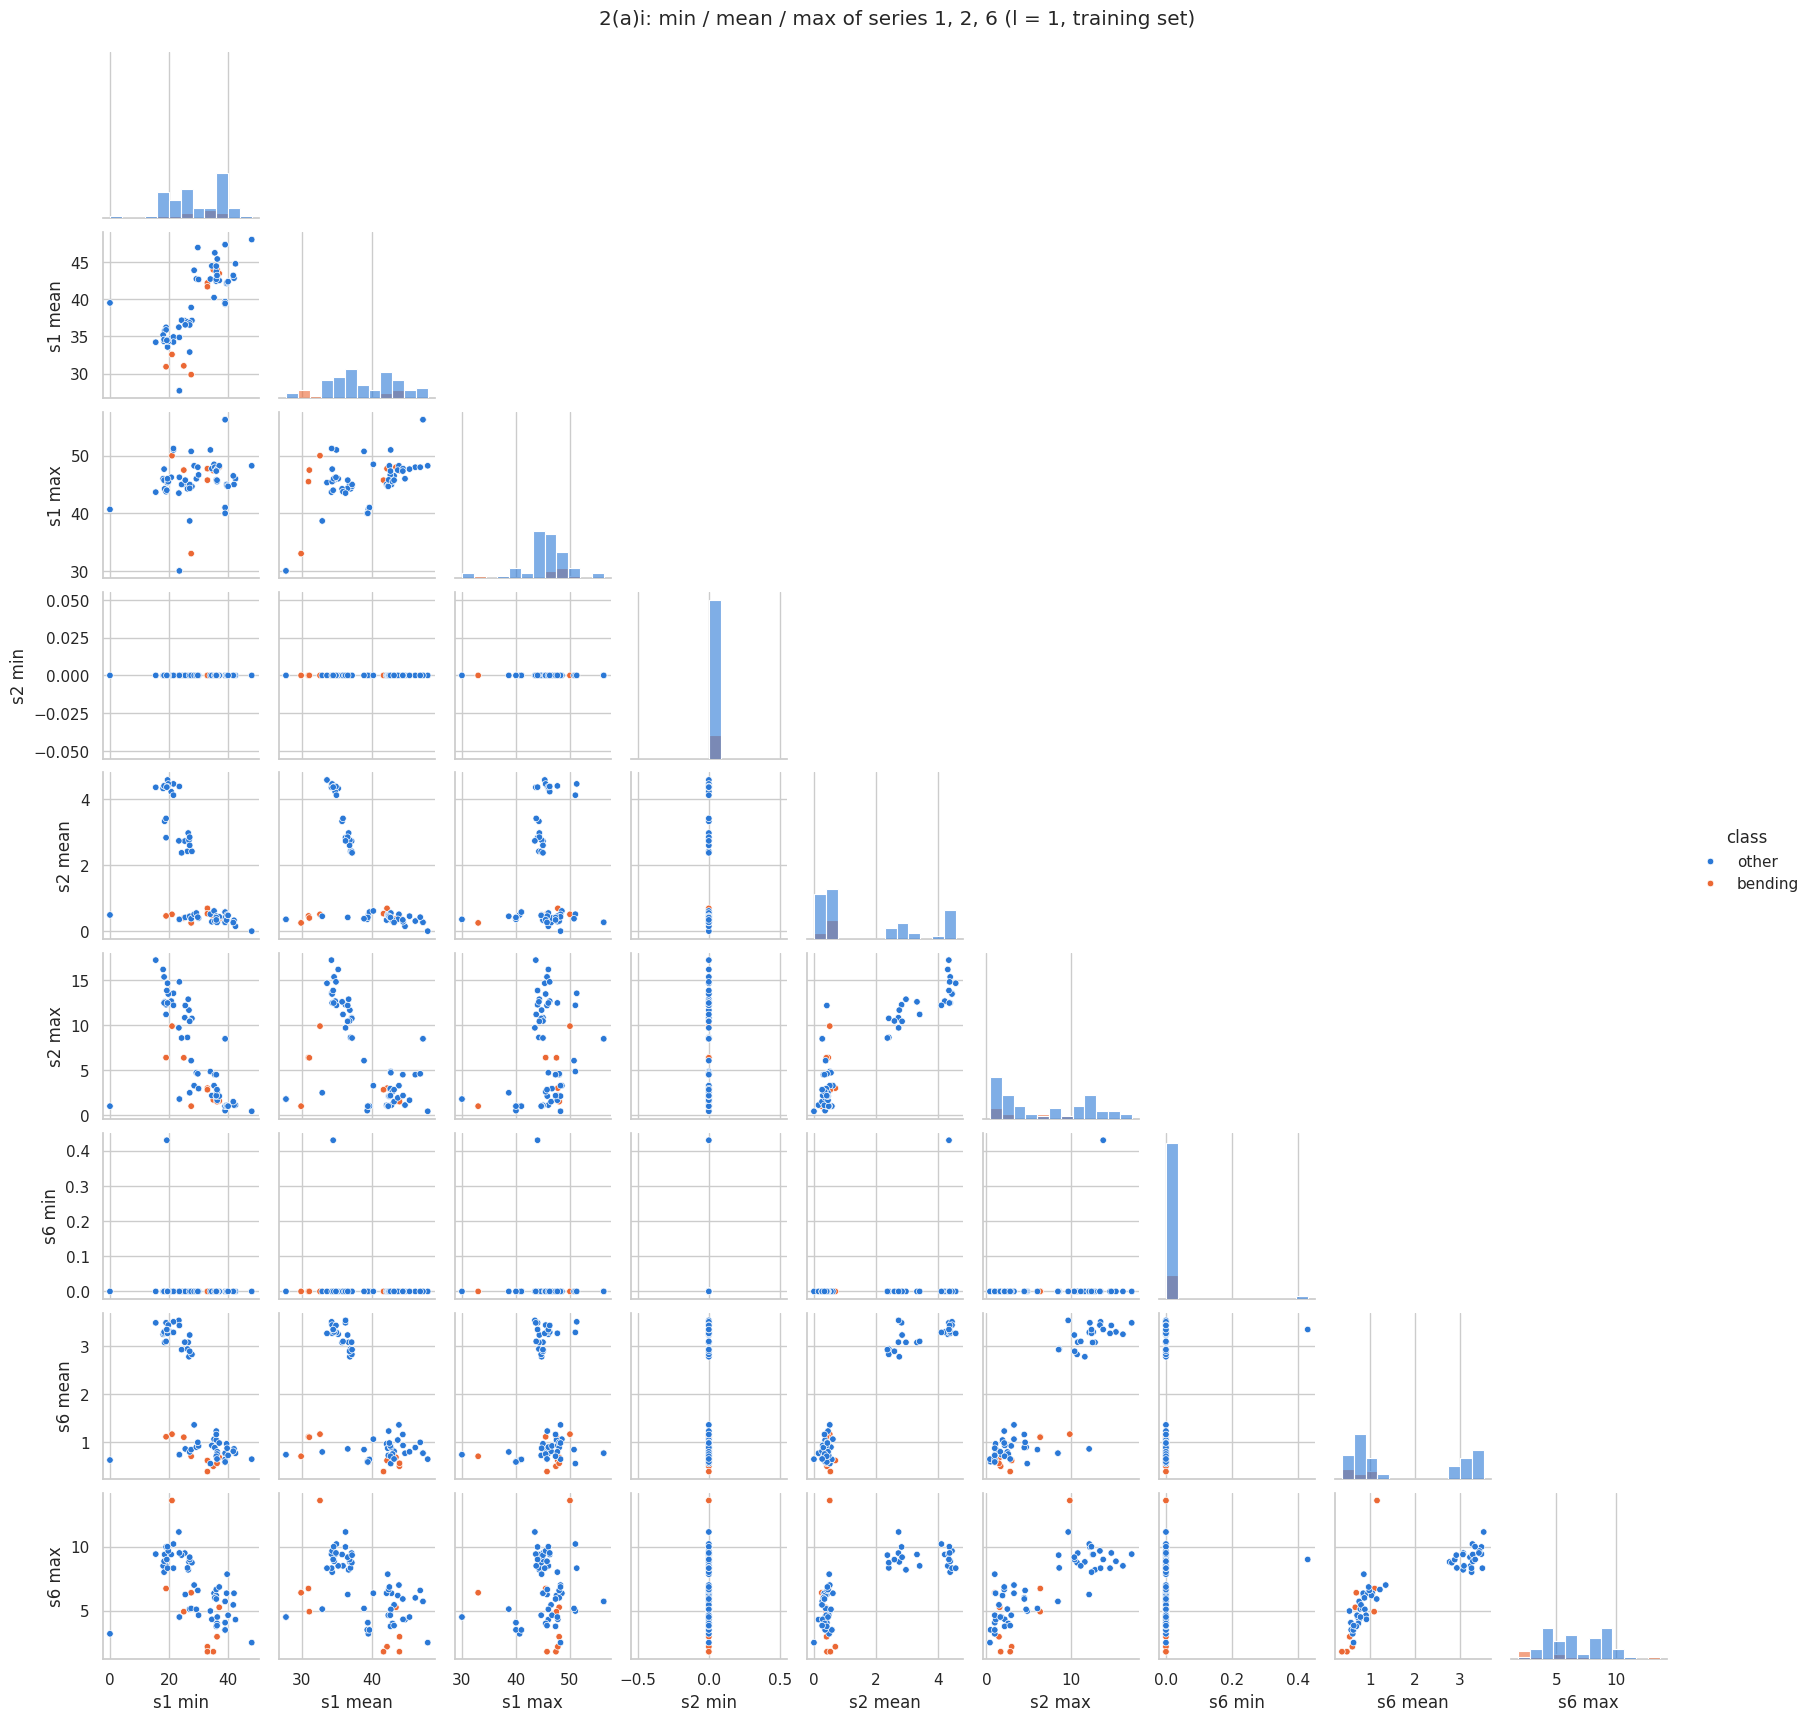

In [15]:
SERIES_IDX = {"avg_rss12": 1, "var_rss12": 2, "var_rss23": 6}
def binary_pairplot(l, part=None, series=("avg_rss12", "var_rss12", "var_rss23"), stats=("min", "mean", "max"), height=1.6):
    # part = which piece (1..l) to plot when l > 1; labels shortened to "s<series #> <stat>".
    Xtr, ytr, _, _ = get_split(l)
    cols, names = [], []
    for s in series:
        for st in stats:
            cols.append(f"{s}_p{part}_{st}" if l > 1 else f"{s}_{st}")
            names.append(f"s{SERIES_IDX[s]} {st}")
    df = Xtr[cols].copy()
    df.columns = names
    df["class"] = np.where(ytr == 1, "bending", "other")
    g = sns.pairplot(df, vars=names, hue="class", hue_order=["other", "bending"], palette=BIN_COLORS,
                     corner=True, height=height, plot_kws=dict(s=22, edgecolor="white", linewidth=0.5),
                     diag_kind="hist", diag_kws=dict(bins=12, alpha=0.6))
    return g
g = binary_pairplot(1, height=1.9)
g.figure.suptitle("2(a)i: min / mean / max of series 1, 2, 6 (l = 1, training set)", y=1.01)
plt.show()

**Observations (2(a)i).**

In these plots, the most distinct separation of data points is made between the "high movement" activities and everything else; rather than between bending and everything else. The s2 mean, s2 max, s6 mean, and s6 max are all quite high for a clearly defined group of non-bending activities (cycling and walking: s2 mean roughly 2.5 to 4.5; s6 mean roughly 3). All of the bending instances fall into the same low-variance category as the static positions.

Within the low-variance group has bending overlaps activity in each individual panel. A single feature which is most effective is s1 mean (avg_rss12_mean): the bending points form two groups, one group is at approximately 30-33 and is lower than nearly all other points; the second group is located at approximately 42-44 and is within the non-bending point cloud. Therefore, although no single two dimensional scatter plot provides a clear linear separation boundary, the combination of "low variance" and an "unusual avg_rss12 value" can provide separation for the majority of the bending points.

s2 min and s6 min (var_rss12_min, var_rss23_min) have a zero value for nearly every instance since every recording's variance series goes down to zero at some point. Therefore, both features contain virtually no information, which is consistent with the bootstrap results of HW3 showing their standard deviations across all instances to be zero.

### 2(a)ii. Break each series into two halves and repeat

Each training time series is split into two halves of 240 observations (sitting/dataset8 is 479 observations, therefore 240 + 239). The series 1, 2 and 6 can then be used to create 2 x 3 x 3 = 18 variables. An 18 × 18 pairplot would be unreadable, so I display the same 9-variable layout as in 2(a)i, once for the first half and once for the second half. Therefore, I will display the same 9 variable arrangement that was displayed previously in 2(a)i for both the first half of the time series and the second half. Pairs that compare the two halves (e.g. the s1 mean of half 1 vs. the s1 mean of half 2) lie almost on the diagonal and therefore add little.

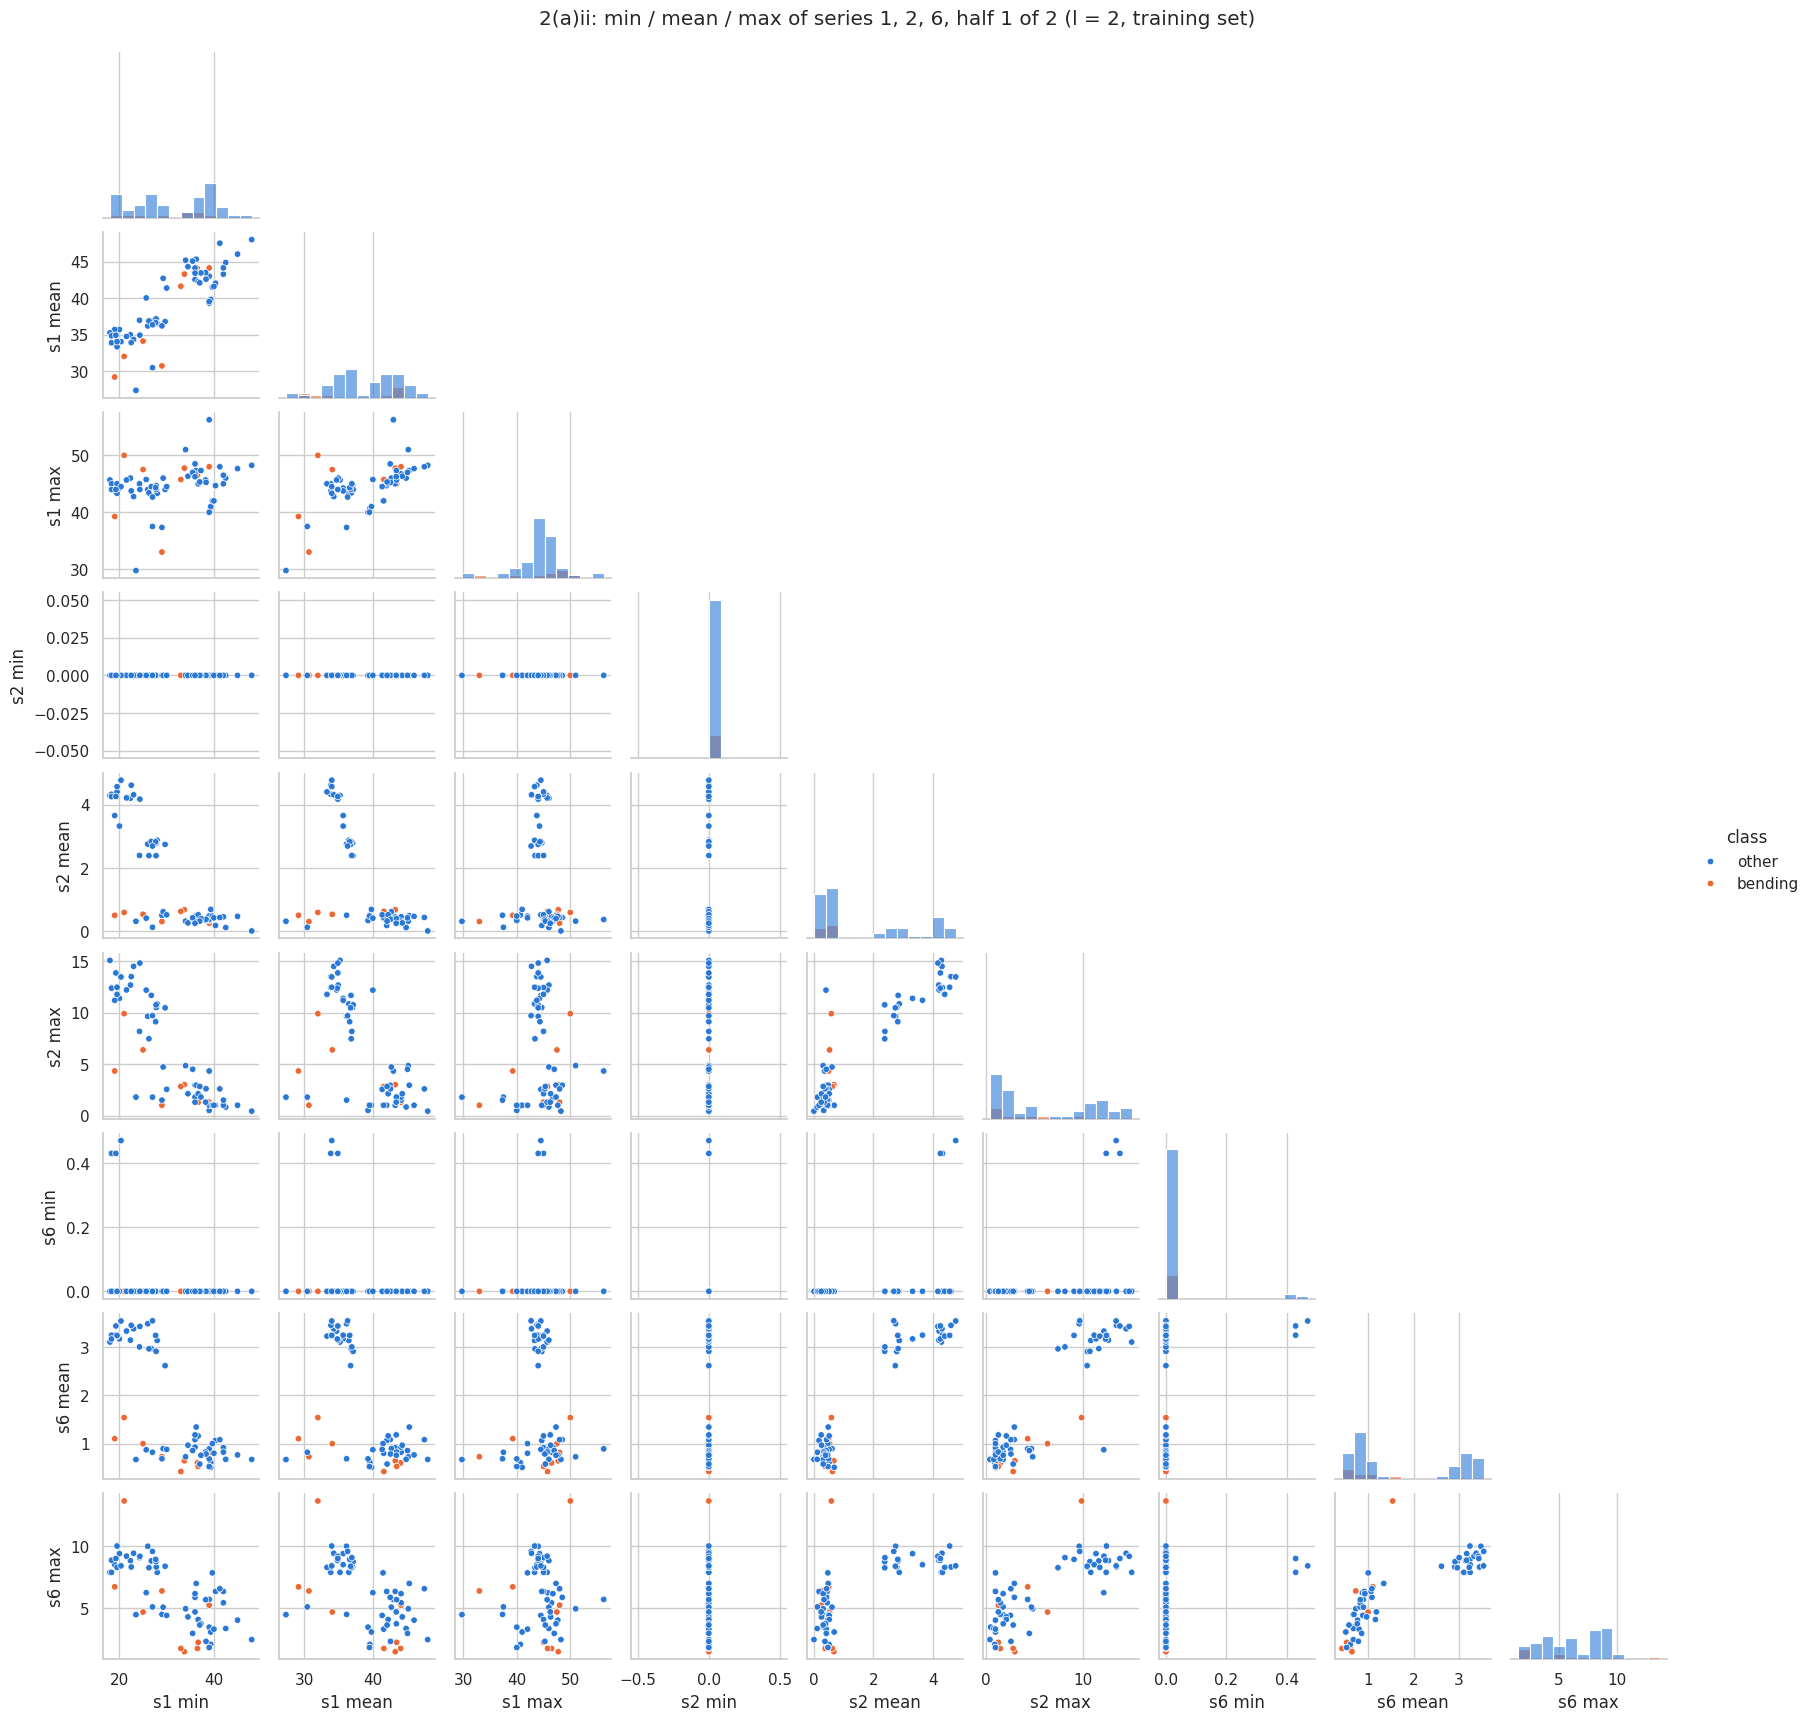

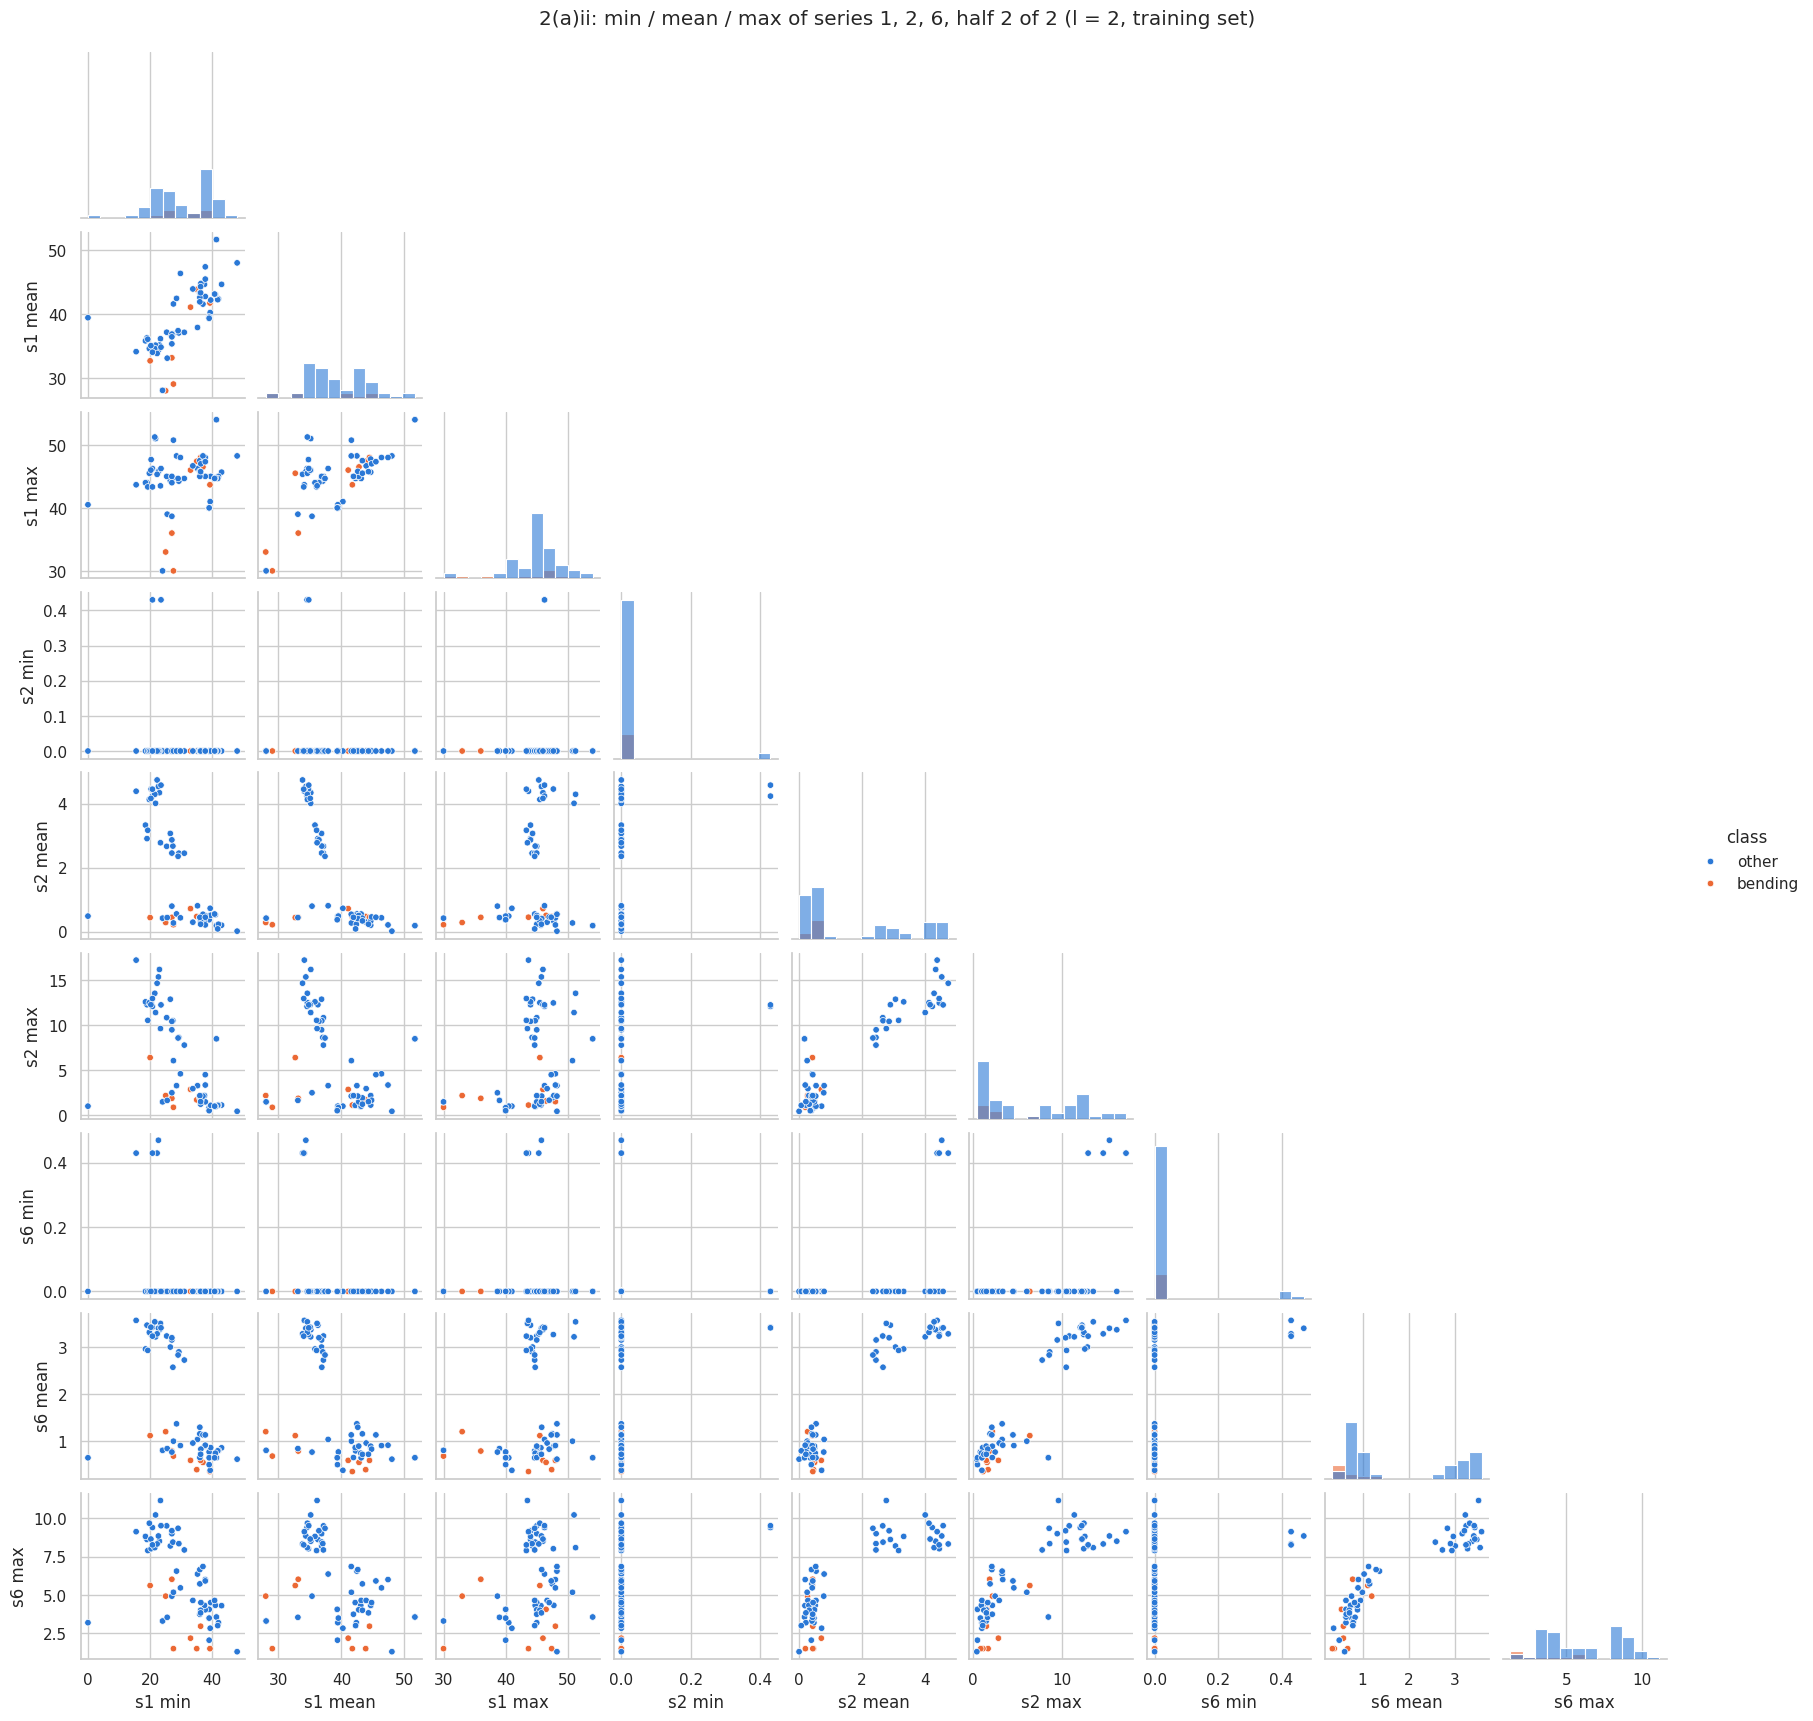

In [16]:
for half in [1, 2]:
    g = binary_pairplot(2, part=half, height=1.9)
    g.figure.suptitle(f"2(a)ii: min / mean / max of series 1, 2, 6, half {half} of 2 (l = 2, training set)", y=1.01)
    plt.show()

Observations (2(a)ii): No significant difference compared to 2(a)i.
- Both halves show similar patterns to 2(a)i. Cycling and walking generally have higher variance in s2 mean/max and s6 mean/max, while bending falls into the low-variance group and overlaps with the static postures. The s2 min and s6 min values remain zero.
- This is expected because each 480-point time series records a person performing an activity for two minutes. The values within each half are fairly similar to those of the full series. The minimum and maximum values of the full recording also come from one of the two halves. For example, the bending instance with an s6 max of around 13.5 has a spike in the first half.
- There are a few differences in the second half. Some bending instances have lower s1 max values (around 30–36), making them slightly easier to distinguish from the other activities. However, the classes still overlap, and no clear separation appears in any individual plot.
- Overall, splitting the time series into halves doubles the number of features but does not add much new information for distinguishing the activities. I use cross-validation in 2(a)iii to check whether smaller segments improve classification accuracy.

### 2(a)iii. Choosing (l, p) with recursive feature elimination and 5-fold cross-validation

**Method :** I created $42l$ features for every value of $l$ from $1$ through $20$ and used sklearn.feature_selection.RFE with an un-penalized logistic regression model ($C=\infty$) to select $p$ features from those $42l$ features, where $p \in \{1,\dots,15\}$. I then evaluated all combinations and chose the best pair of $l$ and $p$ based on their 5-fold cross validation accuracy. The assignment allows RFE as an alternative to selecting features by their p-values . I have included the p-values of the selected model in part 2a(iv).

**Right way vs. wrong way to cross-validate.**

* Wrong way: Perform RFE on all 69 training examples prior to performing cross-validation of a logistic regression model based on the selected features. This creates "data leakage" because the folds used for testing (held-out) have been affected by the process of selecting features, resulting in an overly optimistic estimate of how well the model will perform. With as many as 840 possible features, and only 69 instances, some features could separate the classes strictly due to random chance.

* Right way: Perform feature selection inside each fold. The scaler and RFE are fitted only on the four training folds, and the held-out fold is then used to evaluate the model. For example, if you use a feature selection method called "Recursive Feature Elimination" (RFE) with a "scaler" (a way to normalize data), both should be applied only to the four training folds; then, you will test the performance of the model using the fifth fold. It is okay to create your features in advance for every observation since these features are solely based upon each individual observation's time series and do not rely on the labels or on any other observations.

* Stratified cross validation: The number of "bending" samples in the training set is only nine out of 69 (approx. 13%). A standard five-fold random split can produce some folds with virtually no "bending" samples. To ensure that each fold has approximately the same percentage of "bending" samples as the original sample, I will employ StratifiedKFold to create folds that contain approximately 1.8 "bending" samples per 14 sample fold.

The way that RFE works is that it removes features based on their rank (or importance) in relation to other features. Since we have used step=1, RFE removes exactly one feature at each iteration. Therefore, if we run RFE once per fold, all the way down to a single feature, we can use the ranking_values and determine which features were selected for each of the 15 values of \(p\). Using this approach will produce the exact same results as running RFE 15 times, but it is significantly faster than doing so.

Tie-breaking. There is only a small number of instances (approximately 14) in each validation fold; therefore, the change in accuracy between two consecutive steps is about 1.4 percent. As a result, ties occur frequently. When more than one \((l,p)\) combination produces the highest mean cross-validation accuracy, I will select the combination with the smallest \(l\) value first, then the combination with the smallest \(p\) value. This preference favors the use of a less complex feature space.



In [ ]:
P_MAX = 15
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def rfe_cv_scores(l):
    Xtr, ytr, _, _ = get_split(l)
    X = Xtr.to_numpy()
    acc = np.zeros((5, P_MAX))
    for f, (a, b) in enumerate(skf.split(X, ytr)):
        sc = StandardScaler().fit(X[a]) # fit on training folds only
        Xa, Xb = sc.transform(X[a]), sc.transform(X[b])
        ranking = RFE(logreg("none", max_iter=100), n_features_to_select=1, step=1).fit(Xa, ytr[a]).ranking_
        for p in range(1, P_MAX + 1):
            keep = ranking <= p # exactly RFE(n_features_to_select=p)
            m = logreg("none", max_iter=100).fit(Xa[:, keep], ytr[a])
            acc[f, p - 1] = accuracy_score(ytr[b], m.predict(Xb[:, keep]))
    return acc
t0 = time.time()
rows = []
for l in range(1, 21):
    acc = rfe_cv_scores(l)
    for p in range(1, P_MAX + 1):
        rows.append({"l": l, "p": p, "cv_acc": acc[:, p - 1].mean(), "cv_sd": acc[:, p - 1].std()})
cv_rfe = pd.DataFrame(rows)
print(f"RFE cross-validation finished in {time.time() - t0:.0f} s")
best_rfe = cv_rfe.sort_values(["cv_acc", "l", "p"], ascending=[False, True, True]).iloc[0]
L_A, P_A = int(best_rfe.l), int(best_rfe.p)
print(f"Best (l, p) = ({L_A}, {P_A}),  5-fold CV accuracy = {best_rfe.cv_acc:.4f}")
print("\nAll pairs tied at the top CV accuracy:")
print(cv_rfe[np.isclose(cv_rfe.cv_acc, cv_rfe.cv_acc.max())].to_string(index=False))

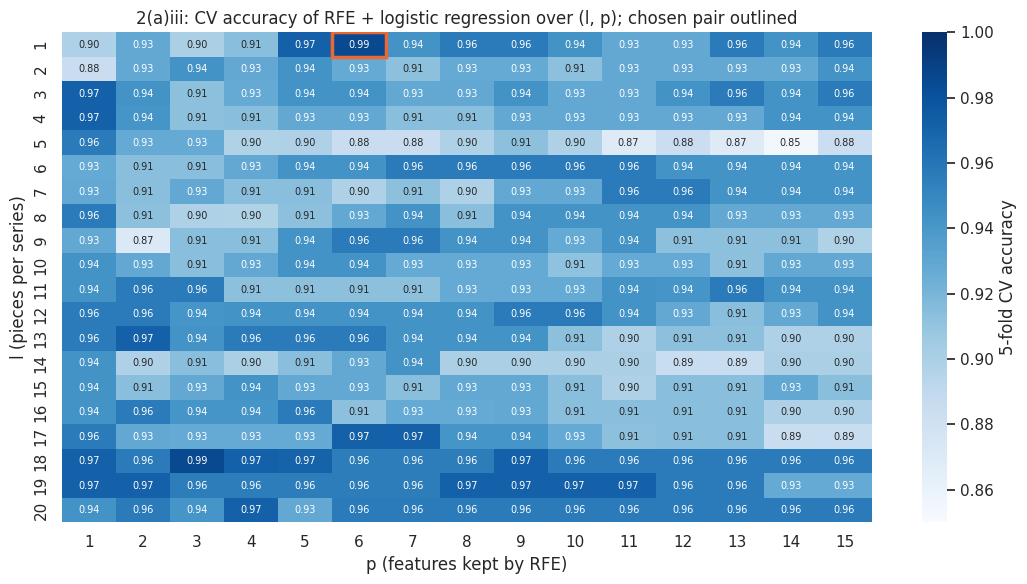

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))
pv = cv_rfe.pivot(index="l", columns="p", values="cv_acc")
sns.heatmap(pv, cmap="Blues", vmin=0.85, vmax=1.0, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.add_patch(plt.Rectangle((P_A - 1, L_A - 1), 1, 1, fill=False, edgecolor=PALETTE[1], lw=2.5))
ax.set_title("2(a)iii: CV accuracy of RFE + logistic regression over (l, p); chosen pair outlined")
ax.set_xlabel("p (features kept by RFE)"); ax.set_ylabel("l (pieces per series)")
plt.tight_layout(); plt.show()

**Result (2(a)iii).**

* The maximum 5-fold cross-validation (CV) accuracy achieved by any of the pairs of parameters $(l,p)$ was **0.9857**, which corresponds to only one sample being incorrectly classified among the total 69. Two of the combinations achieved this level of performance: $(l,p)=(1,6)$ and $(18,3)$. Using the pre-determined tie-breaking criteria (smallest $l$, then smallest $p$), the combination selected is $l=1$ and $p=6$; meaning that out of 42 full-series features, six were selected.

* The accuracy surface is a flat plane. Most cells lie in the range from 0.87 to 0.99 with most pairs of neighboring cells differing by a single instance (or 1.4 points). There does not appear to be any trend in terms of accuracy as a result of dividing the time-series into additional parts. Each time-series segment becomes smaller as $l$ increases (e.g., 24 points at $l=20$), and therefore more subject to noise. At the same time, the number of potential features increases dramatically (e.g., 840 candidate features for only 69 instances), making it easier for RFE to identify random patterns.

* Large values for $p$ are also of no use. On the training folds, the nine (9) positive instances can be separated with just a few features, so adding additional ones only increases the variability.

* As each misclassified instance changes the overall score by 1.4 points, the choice between the two tied pairs (and several pairs at 0.97) is essentially a coin flip. This is discussed further in 2(a)v.

### 2(a)iv. Final model on the full training set: confusion matrix, ROC/AUC, coefficients and p-values

The chosen $(l, p)$ will be refit using all 69 of the training samples. First we'll standardize the data and then use Recursive Feature Elimination (RFE) to reduce the number of features to $p$. Next, we'll fit a logistic regression model with no penalty. All of our coefficients are based on the standardized scale. Our p-values are obtained through the Wald z-test in statsmodels.Logit using the same standardized features.

Selected features: ['avg_rss12_q3', 'var_rss13_max', 'var_rss13_q1', 'avg_rss23_min', 'avg_rss23_max', 'var_rss23_q1']


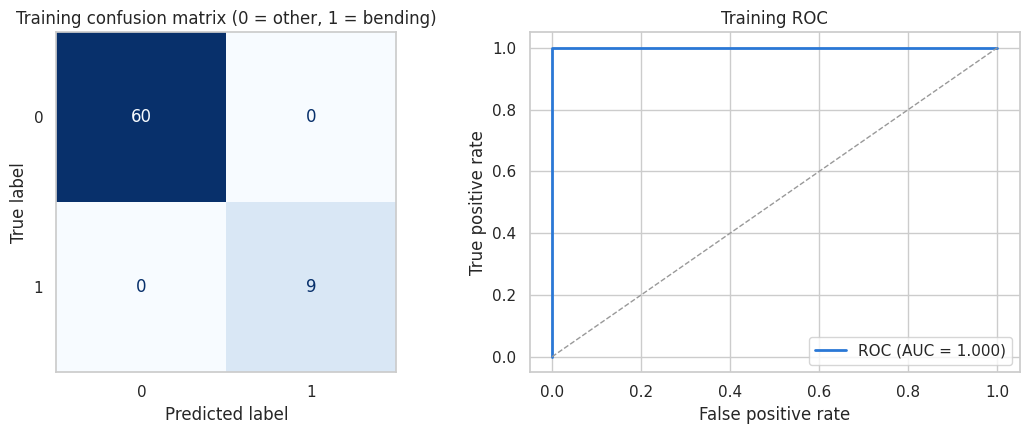

Training accuracy = 1.0000,  training AUC = 1.0000


In [ ]:
Xtr_a, ytr_a, Xte_a, yte_a = get_split(L_A)
scaler_a = StandardScaler().fit(Xtr_a)
Ztr_a = pd.DataFrame(scaler_a.transform(Xtr_a), columns=Xtr_a.columns)
Zte_a = pd.DataFrame(scaler_a.transform(Xte_a), columns=Xte_a.columns)
rfe_a = RFE(logreg("none", max_iter=100), n_features_to_select=P_A, step=1).fit(Ztr_a, ytr_a)
feats_a = list(Ztr_a.columns[rfe_a.support_])
model_a = logreg("none", max_iter=100).fit(Ztr_a[feats_a], ytr_a)
print("Selected features:", feats_a)
prob_tr_a = model_a.predict_proba(Ztr_a[feats_a])[:, 1]
pred_tr_a = model_a.predict(Ztr_a[feats_a])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_tr_a = plot_confusion(ytr_a, pred_tr_a, [0, 1], "Training confusion matrix (0 = other, 1 = bending)", axes[0])
auc_tr_a = plot_roc(ytr_a, prob_tr_a, "Training ROC", axes[1])
plt.tight_layout(); plt.show()
print(f"Training accuracy = {accuracy_score(ytr_a, pred_tr_a):.4f},  training AUC = {auc_tr_a:.4f}")

In [ ]:
sm_a = sm.Logit(ytr_a, sm.add_constant(Ztr_a[feats_a])).fit(disp=0, maxiter=200)
coef_table_a = pd.DataFrame({
    "beta (sklearn)": np.r_[model_a.intercept_, model_a.coef_.ravel()],
    "beta (statsmodels)": sm_a.params.values,
    "std. error": sm_a.bse.values,
    "z": sm_a.tvalues.values,
    "p-value": sm_a.pvalues.values,
}, index=["intercept"] + feats_a)
print("statsmodels converged:", sm_a.mle_retvals.get("converged"))
display(coef_table_a.style.format({"beta (sklearn)": "{:.3f}", "beta (statsmodels)": "{:.3f}",
                                   "std. error": "{:.3e}", "z": "{:.2e}", "p-value": "{:.4f}"}))

statsmodels converged: False


,beta (sklearn),beta (statsmodels),std. error,z,p-value
intercept,-12.196,-45.490,1.738e+05,-2.62e-04,0.9998
avg_rss12_q3,-3.997,-14.832,1.076e+05,-1.38e-04,0.9999
var_rss13_max,3.489,10.998,1.739e+05,6.33e-05,0.9999
var_rss13_q1,-3.406,-3.108,4.811e+05,-6.46e-06,1.0000
avg_rss23_min,6.979,25.091,2.301e+05,1.09e-04,0.9999
avg_rss23_max,5.103,17.522,2.386e+05,7.34e-05,0.9999
var_rss23_q1,-4.290,-24.231,6.950e+05,-3.49e-05,1.0000


**Result (2(a)iv).**

The selected features are: average RSS12 Q3, variance RSS13 maximum, variance RSS13 Q1, average RSS23 minimum, average RSS23 maximum, and variance RSS23 Q1.

The performance of the model on the training data: The model correctly classified each of the 69 training instances (with 60 true negatives and 9 true positives). The Area Under the Curve (AUC) for the training data is 1.000.

The table reports two fits of the same model (scikit-learn and statsmodels). statsmodels is unable to find a convergent solution, and its estimated standard errors are extremely large (between $10^5$ and $10^6$). As such, its z-statistics are very close to zero, and every p-value falls within the range 0.9998 to 1.0000. are very close to zero. Furthermore, the estimated p-values for every parameter in each model fall within the range of 0.9998-1.0000.

High p-values do not indicate that a feature is irrelevant. High p-values are produced when features perfectly separate the two groups, which was illustrated in Figure 2(a)vi. Because the features perfectly divide the two groups, the logistic regression coefficients can continually grow without ever having a defined maximum likelihood estimate. As a result, the standard error will continually increase and the p-value will continually approach 1.

The coefficients produced by both models have the same signs; however, the coefficients produced by statsmodels tend to be 3-6 times larger than those produced by scikit-learn. The reason for this difference is that statsmodels kept iterating, with the coefficients growing toward infinity, until it reached its iteration limit without converging. Scikit-learn's L-BFGS optimizer on the other hand, stopped after 13 iterations as soon as it met its gradient tolerance. Due to "perfect separation," the coefficient estimates are not reliable. However, the signs and predictions will remain consistent.

I chose to use RFE (recursive feature elimination) using coefficient magnitude rather than feature selection through p-values in 2(a)iii because the p-values in this instance were not reliable enough to rank the importance of each feature.

### 2(a)v. Test-set performance

The 19 test instances are broken into the same $l$ pieces, standardized with the **training** scaler, and reduced to the same $p$ features.

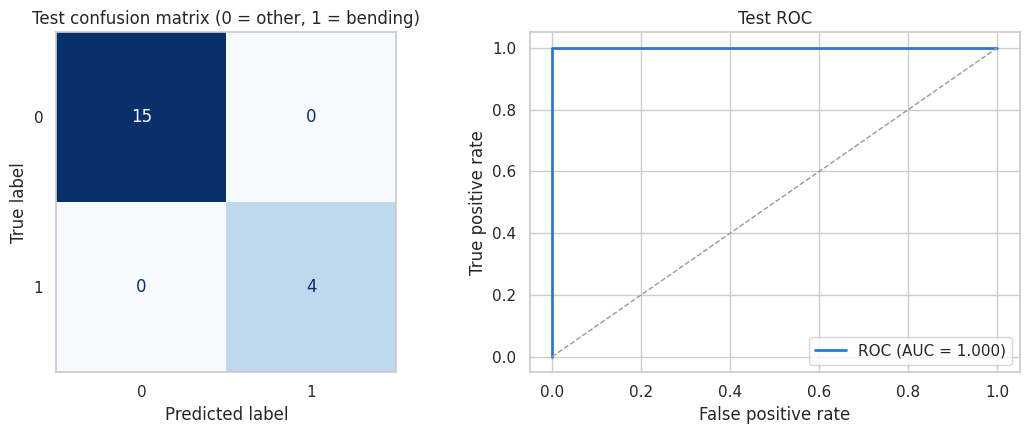

Test accuracy = 1.0000   vs   5-fold CV accuracy = 0.9857
Test AUC = 1.0000


In [ ]:
prob_te_a = model_a.predict_proba(Zte_a[feats_a])[:, 1]
pred_te_a = model_a.predict(Zte_a[feats_a])
test_acc_a = accuracy_score(yte_a, pred_te_a)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(yte_a, pred_te_a, [0, 1], "Test confusion matrix (0 = other, 1 = bending)", axes[0])
auc_te_a = plot_roc(yte_a, prob_te_a, "Test ROC", axes[1])
plt.tight_layout(); plt.show()
print(f"Test accuracy = {test_acc_a:.4f}   vs   5-fold CV accuracy = {best_rfe.cv_acc:.4f}")
print(f"Test AUC = {auc_te_a:.4f}")

In [ ]:
# Transparency check (not used for model choice): every (l, p) pair tied at the best CV accuracy, refit and tested.
for _, r in cv_rfe[np.isclose(cv_rfe.cv_acc, cv_rfe.cv_acc.max())].iterrows():
    l, p = int(r.l), int(r.p)
    Xt, yt, Xs_, ys_ = get_split(l)
    sc = StandardScaler().fit(Xt)
    keep = RFE(logreg("none", max_iter=100), n_features_to_select=p).fit(sc.transform(Xt), yt).support_
    m = logreg("none", max_iter=100).fit(sc.transform(Xt)[:, keep], yt)
    print(f"(l, p) = ({l:2d}, {p}): CV acc {r.cv_acc:.4f} | test acc {accuracy_score(ys_, m.predict(sc.transform(Xs_)[:, keep])):.4f}")

(l, p) = ( 1, 6): CV acc 0.9857 | test acc 1.0000
(l, p) = (18, 3): CV acc 0.9857 | test acc 0.9474


**Result (2(a)v).**

* Test performance accuracy = ***1.000*** (19/19), test performance AUC = 1.000, compared with 5-fold CV performance accuracy = 0.9857

* The two values are consistent. There are 19 test cases. If an error is made on a single case then accuracy drops by 5.3%. Therefore, there is no way to differentiate between 1.000 and 0.986.

Three caveats make the test score look better than it should be read:

* Duplicates: There are three test cases that are identical to the training cases (i.e., cycling/dataset1 = dataset15, lying/dataset1 = dataset15, and lying/dataset3 = dataset11). See Section 0 for the duplicate checking procedure.All three are non-bending and, being identical to training files, are trivially classified correctly.

* Sample size. The test set has only 4 bending instances.

* Selection Noise. The transparency check cell above refits the other pair tied for the best CV score $(l,p) = (18, 3)$. It has a score of 18 out of 19 instances on the test set, which equals 0.947. This indicates that the CV procedure was unable to distinguish between these two models and that the test set has a single instance that distinguishes them. However, I did not use this test result to choose the model.. The selection of the model was determined based on the tie-breaker rule prior to examining the test data.

### 2(a)vi. Are the classes well separated enough to destabilize logistic regression?

Three checks on the training data: (1) training accuracy and the smallest margin of the fitted model, (2) how the coefficient size changes as the optimizer is allowed more iterations, and (3) what the unpenalized maximum likelihood fit in statsmodels reports.

In [ ]:
Xs = Ztr_a[feats_a].to_numpy()
rows = []
for it in [5, 10, 25, 50, 100, 1000, 10000]:
    m = logreg("none", max_iter=it).fit(Xs, ytr_a)
    rows.append({"max_iter": it, "iterations used": int(m.n_iter_[0]), "max |beta|": np.abs(m.coef_).max(),
                 "train acc": accuracy_score(ytr_a, m.predict(Xs)),
                 "train log-loss": log_loss(ytr_a, m.predict_proba(Xs)[:, 1])})
display(pd.DataFrame(rows).style.format({"max |beta|": "{:.2f}", "train acc": "{:.3f}", "train log-loss": "{:.2e}"}))
dec = model_a.decision_function(Xs)
print("Smallest linear score among bending instances:", dec[ytr_a == 1].min().round(2))
print("Largest  linear score among other   instances:", dec[ytr_a == 0].max().round(2))
print("statsmodels standard errors:", sm_a.bse.round(1).to_dict())
# Separability is not specific to the chosen pair: check l = 1 with all 42 features.
X1, y1, _, _ = get_split(1)
big = LogisticRegression(C=1e6, max_iter=20000).fit(StandardScaler().fit_transform(X1), y1)
print("l = 1, all 42 features, C = 1e6: training accuracy =",
      accuracy_score(y1, big.predict(StandardScaler().fit_transform(X1))))

,max_iter,iterations used,max |beta|,train acc,train log-loss
0,5,5,1.94,1.000,2.62e-02
1,10,10,4.95,1.000,1.16e-03
2,25,13,6.98,1.000,1.58e-04
3,50,13,6.98,1.000,1.58e-04
4,100,13,6.98,1.000,1.58e-04
5,1000,13,6.98,1.000,1.58e-04
6,10000,13,6.98,1.000,1.58e-04


Smallest linear score among bending instances: 6.44
Largest  linear score among other   instances: -5.38
statsmodels standard errors: {'const': 173848.6, 'avg_rss12_q3': 107561.7, 'var_rss13_max': 173860.6, 'var_rss13_q1': 481089.2, 'avg_rss23_min': 230101.8, 'avg_rss23_max': 238634.7, 'var_rss23_q1': 695028.1}
l = 1, all 42 features, C = 1e6: training accuracy = 1.0


**Answer (2(a)vi): Yes. The training data set can be The training data are perfectly linearly separable, so the logistic regression model parameters will be unstable.

Evidence:

The margin exists. Each bending event using the six selected variables will have a linear score no lower than 6.44; each other event will have a linear score no higher than -5.38. Therefore there is a margin as opposed to simply being correctly classified. Additionally, separability does not apply only to the six selected variables: with l=1 and all 42 variables, an almost unpenalized fit (C=10^6) can achieve 100% training accuracy.

The coefficients are not identified (not uniquely determined).. When using the max_iter option in the table, setting the iteration limit to 5 or 10 will yield max $|\beta|$ of 1.94 and 4.95, respectively, but both will produce 100% training accuracy. The L-BFGS algorithm stops after 13 iterations due to the fact that the gradient is smaller than the specified tolerance level (training log-loss $1.6 \times 10^{-4}$), rather than because it has reached a maximum; increasing $\beta$ would continue to decrease the loss toward 0. Any of these coefficient vectors classifies the training data perfectly classify the training data perfectly.

The statsmodels software will give you a warning that you have had a "perfect-separation" problem and will not be able to find the MLE. Statsmodels also gives very large standard errors for the parameters ($10^5$ to $7 \times 10^5$) and therefore gives p-values that are essentially 1 (2(a)iv).

Consequences: Accuracy and Area Under Curve (AUC) can be used to rank and classify observations, but the coefficients and their associated p-values have no meaning. Common solutions include using regularization techniques such as the L1 model in 2(b), or Ridge; using early stopping as described in the footnote; or using Firth's Bias Reduced Logistic Regression.

### 2(a)vii. Class imbalance and case-control sampling

The confusion matrices indicate that there were 9 bending instances compared to 60 non-bending instances for the training data and 4 bending instances compared to 15 non-bending instances for the test data; thus, approximately 13 percent of the training data was made up of the positive class (bending), which means that the classes are not equally distributed.

The use of case-control sampling in which all nine bending instances were selected along with nine randomly chosen non-bending instances from the 60 non-bending instances resulting in a sample prevalence of $\tilde\pi = 0.5$ as opposed to the true prevalence of $\pi = 9/69$. A logistic regression model fit to the sample would provide consistent slope estimates, however the intercept will be shifted because of the sampling. A correction for the shift can be found in ESL §4.4, ISLR lecture notes.

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi}.$$

Using the same l and p variables that were identified in 2(a)iii, I will then train a model with these variables using the 18 instances from the Case-Control sample. Once trained, I will make an adjustment to the intercept of the model, and evaluate its performance against the entire training set as well as the testing set.

pi = 0.1304, pi_tilde = 0.50, intercept -6.348 -> -8.245 (shift -1.897)


,"beta (case-control, adjusted)"
intercept,-8.245
avg_rss12_q3,-4.116
var_rss13_max,0.404
var_rss13_q1,-2.395
avg_rss23_min,1.949
avg_rss23_max,7.137
var_rss23_q1,-3.913


Training: accuracy = 0.9855, AUC = 1.0000
Test: accuracy = 1.0000, AUC = 1.0000


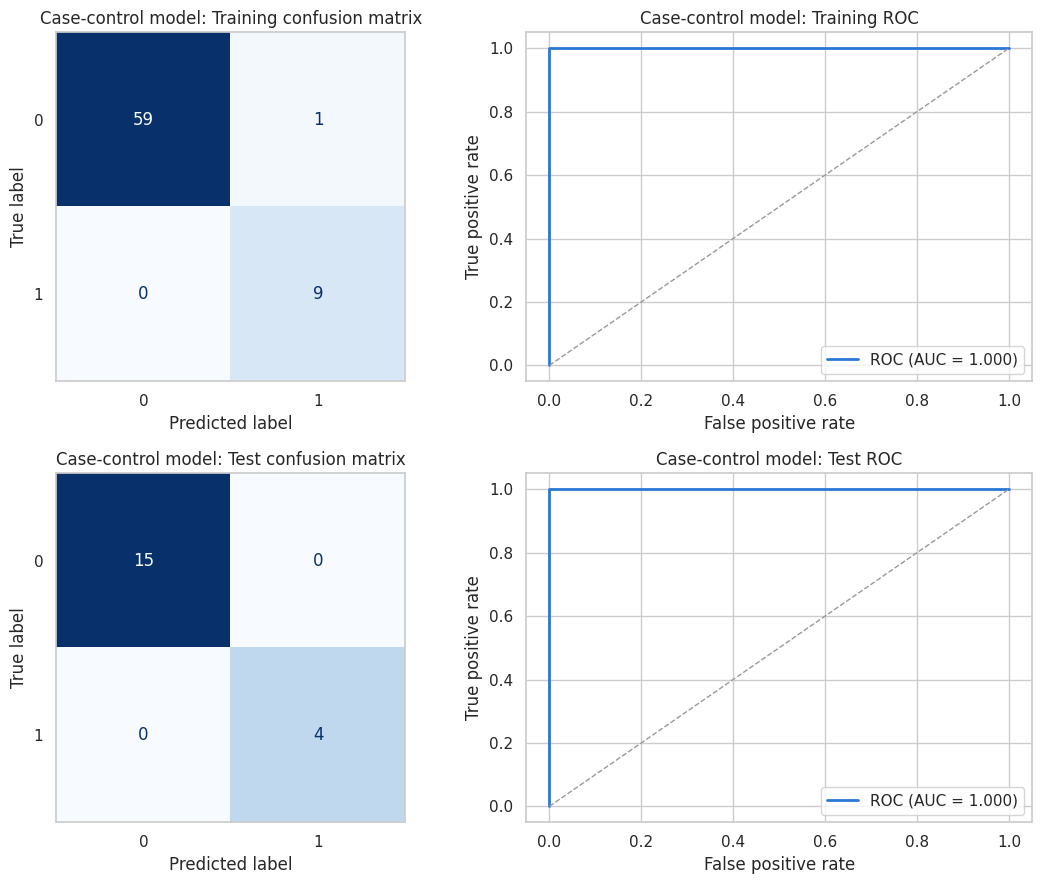

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
case_idx = np.flatnonzero(ytr_a == 1)
ctrl_idx = rng.choice(np.flatnonzero(ytr_a == 0), size=len(case_idx), replace=False)
cc_idx = np.r_[case_idx, ctrl_idx]
pi_true = ytr_a.mean()
pi_cc = ytr_a[cc_idx].mean()
cc = logreg("none", max_iter=100).fit(Ztr_a.loc[cc_idx, feats_a], ytr_a[cc_idx])
shift = np.log(pi_true / (1 - pi_true)) - np.log(pi_cc / (1 - pi_cc))
b0_raw = cc.intercept_[0]
cc.intercept_ = cc.intercept_ + shift# adjusted model
print(f"pi = {pi_true:.4f}, pi_tilde = {pi_cc:.2f}, intercept {b0_raw:.3f} -> {cc.intercept_[0]:.3f} (shift {shift:.3f})")
display(pd.DataFrame({"beta (case-control, adjusted)": np.r_[cc.intercept_, cc.coef_.ravel()]},
                     index=["intercept"] + feats_a).round(3))
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, (Z, y, name) in enumerate([(Ztr_a, ytr_a, "Training"), (Zte_a, yte_a, "Test")]):
    pr = cc.predict_proba(Z[feats_a])[:, 1]
    pd_ = (pr >= 0.5).astype(int)
    plot_confusion(y, pd_, [0, 1], f"Case-control model: {name} confusion matrix", axes[row, 0])
    a = plot_roc(y, pr, f"Case-control model: {name} ROC", axes[row, 1])
    print(f"{name}: accuracy = {accuracy_score(y, pd_):.4f}, AUC = {a:.4f}")
plt.tight_layout(); plt.show()

**Result (2(a)vii).**

The classes are indeed imbalanced with 9 instances of "bending" compared to 60 instances of "other" in the training set (13%), and 4 instances of "bending" compared to 15 instances of "other" in the test set (21%). Therefore, a simple classifier that predicts "other" every time would achieve 87% accuracy on the training data, and this is represented by the lower bound of the heatmap in 2(b).

Case-Control Model. There are 9 cases and 9 controls that were randomly sampled ($\tilde\pi = 0.5$). The fitted intercept $-6.348$ is adjusted for the difference between the sample and true class proportions with the correction factor of $\log(9/60) - \log(1) = -1.897$, so that the adjusted intercept becomes $-8.245$. This brings the predicted probabilities back to their actual base rate of 13%, as opposed to being centered at 50% as though half of the instances are bending.

Performance. training: 68/69 (accuracy 0.9855; one false positive), auc 1.000 test: 19/19 (accuracy 1.000), auc 1.000

The case-control model has the same AUC as the full-data model on both sets, and one additional training error, because it only had access to 18 of the 69 instances. In this case, the class imbalance did not cause harm to the full-data model because the classes were separable. Case-control sampling provides benefits when the data is large and the cost of discarding controls is low; however, at 69 instances, discarding 51 controls results in a loss of information without any computational advantage.

## 2(b) Binary classification using L1-penalized logistic regression

### 2(b)i. Cross-validating (l, C)

Same problem, but instead of using p-values/RFE for feature selection, I used the L1 penalty. The features were standardized in each fold (since the L1 penalty does not have scale invariance). I used the liblinear solver as suggested and searched $l \in \{1,\dots,20\}$ and $C \in \{10^{-2}, 10^{-1.5}, \dots, 10^{2}\}$ (9 values; $C = 1/\lambda$ represents the budget) using the same stratified 5-fold split as in 2(a)iiii. Both scaler and model were refit within each fold via a Pipeline to ensure correct cross validation. Ties at the top were resolved by selecting smaller $l$ followed by smaller $C$ (larger penalty, sparser model).

L1 grid finished in 4 s
Best (l, C) = (11, 1),  5-fold CV accuracy = 0.9857


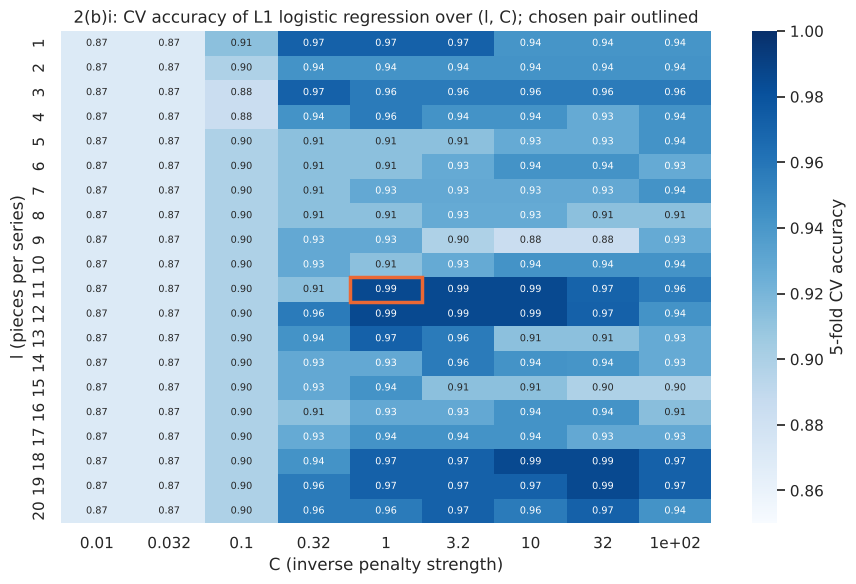

In [ ]:
Cs = np.logspace(-2, 2, 9)
def cv_grid(make_model, binary, ls=range(1, 21), Cs=Cs):
    rows = []
    for l in ls:
        Xtr, ytr, _, _ = get_split(l, binary=binary)
        X = Xtr.to_numpy()
        for C in Cs:
            accs = []
            for a, b in skf.split(X, ytr):
                m = make_model(C).fit(X[a], ytr[a])
                accs.append(accuracy_score(ytr[b], m.predict(X[b])))
            rows.append({"l": l, "C": C, "cv_acc": np.mean(accs), "cv_sd": np.std(accs)})
    return pd.DataFrame(rows)
t0 = time.time()
cv_l1 = cv_grid(lambda C: make_pipeline(StandardScaler(), logreg("l1", C=C)), binary=True)
print(f"L1 grid finished in {time.time() - t0:.0f} s")
best_l1 = cv_l1.sort_values(["cv_acc", "l", "C"], ascending=[False, True, True]).iloc[0]
L_B, C_B = int(best_l1.l), float(best_l1.C)
print(f"Best (l, C) = ({L_B}, {C_B:.4g}),  5-fold CV accuracy = {best_l1.cv_acc:.4f}")
fig, ax = plt.subplots(figsize=(9, 6))
pv = cv_l1.pivot(index="l", columns="C", values="cv_acc")
pv.columns = [f"{c:.2g}" for c in pv.columns]
sns.heatmap(pv, cmap="Blues", vmin=0.85, vmax=1.0, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.add_patch(plt.Rectangle((list(Cs).index(C_B), L_B - 1), 1, 1, fill=False, edgecolor=PALETTE[1], lw=2.5))
ax.set_title("2(b)i: CV accuracy of L1 logistic regression over (l, C); chosen pair outlined")
ax.set_xlabel("C (inverse penalty strength)"); ax.set_ylabel("l (pieces per series)")
plt.tight_layout(); plt.show()

Nonzero coefficients: 8 of 462


,beta (standardized)
avg_rss23_p2_q1,1.365
avg_rss12_p6_max,-0.791
avg_rss23_p10_min,0.713
avg_rss23_p2_median,0.506
var_rss13_p8_median,-0.316
avg_rss23_p1_max,0.280
var_rss23_p9_std,-0.135
var_rss23_p10_max,-0.042


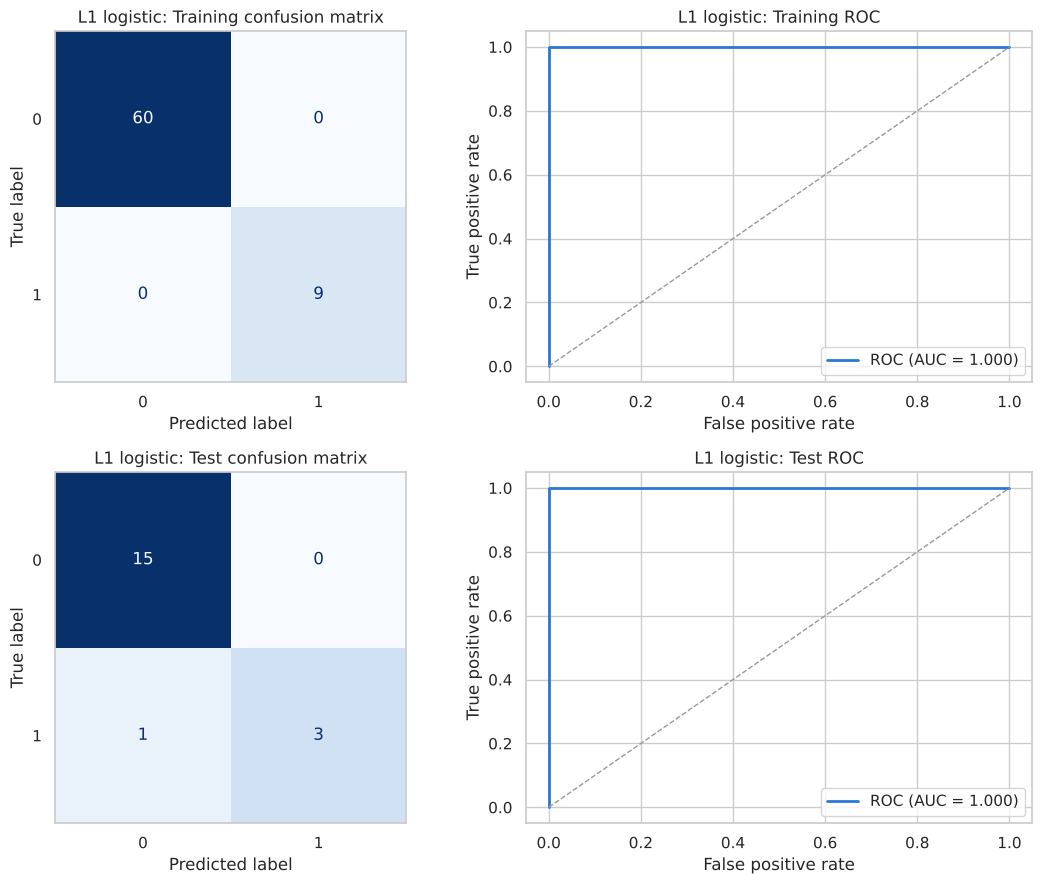

Training: accuracy = 1.0000, AUC = 1.0000
Test: accuracy = 0.9474, AUC = 1.0000


In [ ]:
Xtr_b, ytr_b, Xte_b, yte_b = get_split(L_B)
model_b = make_pipeline(StandardScaler(), logreg("l1", C=C_B)).fit(Xtr_b, ytr_b)
coef_b = pd.Series(model_b[-1].coef_.ravel(), index=Xtr_b.columns)
nz_b = coef_b[coef_b != 0].sort_values(key=np.abs, ascending=False)
print(f"Nonzero coefficients: {len(nz_b)} of {len(coef_b)}")
display(nz_b.to_frame("beta (standardized)").round(3))
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
res_b = {}
for row, (X, y, name) in enumerate([(Xtr_b, ytr_b, "Training"), (Xte_b, yte_b, "Test")]):
    pr, pd_ = model_b.predict_proba(X)[:, 1], model_b.predict(X)
    plot_confusion(y, pd_, [0, 1], f"L1 logistic: {name} confusion matrix", axes[row, 0])
    res_b[name] = (accuracy_score(y, pd_), plot_roc(y, pr, f"L1 logistic: {name} ROC", axes[row, 1]))
plt.tight_layout(); plt.show()
for k, (a, u) in res_b.items():
    print(f"{k}: accuracy = {a:.4f}, AUC = {u:.4f}")

**Result (2(b)i).**

* Best pair: $l=11$, $C=1$ ($\lambda = 1$), 5-fold CV accuracy of 0.9857, which is equal to the best RFE model's.

* The heat map indicates what will be the predicted penalty path. At a value of $C \le 0.032$, the penalty makes all of the coefficients zero, so the model predicts "other" for every instance. This provides precisely the same rate as the majority (60/69 = 0.87). There is an increase in accuracy from $C = 0.1$ to $C = 1$, followed by accuracy levelling off or dipping slightly as the penalty becomes weaker, leading to the fitting being closer to the un-penalized solution which is unstable. Rows $l = 11, 12$ and $l = 18, 19$ are the best; however, as before, adjacent cells are different by approximately one individual.

* The model that has been trained on the data uses eight of the 462 variables (listed in the table), the L1 penalty was used for variable selection.

* Training: 69/69, AUC 1.000. Test: 18/19, accuracy 0.9474, AUC 1.000.
* The single error is an instance of bending classified as "other". An AUC of 1 indicates that although there was a misclassification (threshold effect), the model classified each bending test instance with a higher probability than all of the non-bending instances; therefore, the misclassified bending instance had a lower probability than 0.5 but a higher probability than any non-bending instance.

### 2(b)ii. L1 penalty vs. p-value/RFE selection

In [ ]:
summary_b = pd.DataFrame({
    "chosen l": [L_A, L_B],
    "features used": [P_A, len(nz_b)],
    "5-fold CV accuracy": [best_rfe.cv_acc, best_l1.cv_acc],
    "test accuracy": [test_acc_a, res_b["Test"][0]],
    "test AUC": [auc_te_a, res_b["Test"][1]],
}, index=["RFE / p-value selection, unpenalized", "L1-penalized"])
display(summary_b.style.format({"5-fold CV accuracy": "{:.4f}", "test accuracy": "{:.4f}", "test AUC": "{:.4f}"}))

,chosen l,features used,5-fold CV accuracy,test accuracy,test AUC
"RFE / p-value selection, unpenalized",1,6,0.9857,1.0000,1.0000
L1-penalized,11,8,0.9857,0.9474,1.0000


**Answer (2(b)ii).**

The two methods perform equally well in terms of their cross-validated (CV) accuracy (0.9857). When it comes to the test data set, RFE achieves 19/19 correct predictions, while L1 makes 18/19. Both have an Area Under the Curve (AUC) value of 1.000. It's difficult to say which is better when there's only one instance of error among 19 test cases; additionally, 2(a)v demonstrated that a similarly performing RFE pair can also achieve 18/19 correct predictions.

* **Reliability**: L1 is better. The penalty makes the optimization problem strictly well-posed even if the classes can be separated. Thus, the L1 coefficients will always be a single, finite solution. On the other hand, the unpenalized model that forms the basis of p-value/RFE selection does not have a finite MLE for this problem (2(a)vi). Therefore, the unpenalized model's coefficients are dependent upon the optimization algorithm used, and all of the p-values are close to one. Simply stated, the p-value selection method cannot be implemented as described in the assignment on the current dataset.

* **Simplicity**: L1 is easier. Selection and fitting occur with a single convex fitting. Also, $C$ is the only tuning parameter. It required about 4 seconds to complete the entire $(l, C)$ grid, whereas the RFE search over $(l, p)$ required roughly 170 seconds due to requiring one backward elimination for each fold. Additionally, the p-value method requires an additional library (statsmodels or R), a pruning rule, and then a re-fit.

The L1 penalized model is my overall preference because it has the same level of accuracy as the other model, its coefficients are stable, and it is easier to implement.

## 2(c) Multi-class classification (all seven activities)

### 2(c)i. L1-penalized multinomial logistic regression

$l$ and $C$ were determined as described in 2(b)i (using the same grid, the same stratified folds, scaling within the pipeline, and the same tie-breaking procedure), but with a seven-class label. The **saga** solver is used to fit a true multinomial (softmax) model with an L1 penalty. I am using **tol=1e-3** and **max_iter=1000**. With the default tol=1e-4, the large-$C$ models fit on 840 features require thousands of epochs (since these data sets are nearly linearly separable, as discussed in 2(a)vi), and the grid runs for approximately 45 minutes rather than approximately 5 minutes.

**bending2** only has 4 training examples. Therefore, when using 5 folds, there will be one fold that does not contain a bending2 example. This cannot be avoided with only 4 instances.. However, **StratifiedKFold** will still balance all other classes in each of the 5 folds.

Multinomial L1 grid finished in 220 s
Best (l, C) = (2, 31.62),  5-fold CV accuracy = 0.9286


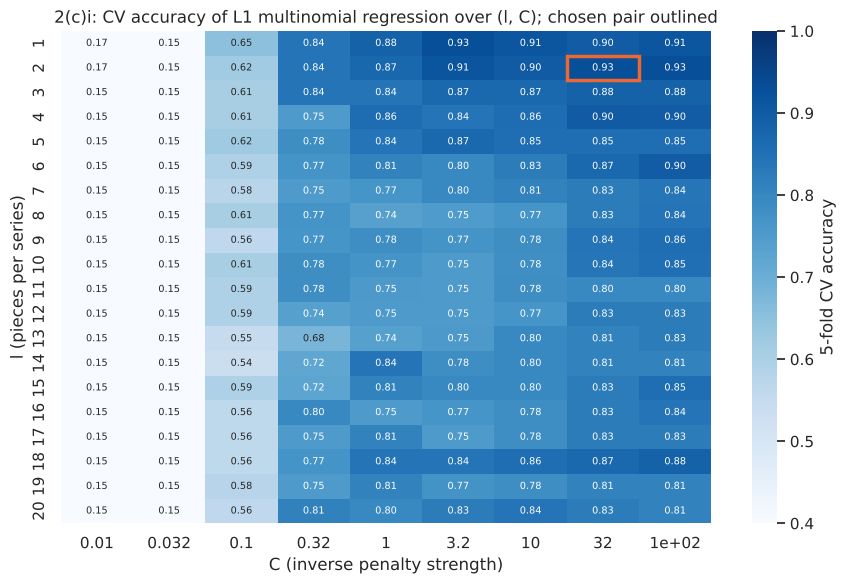

In [ ]:
t0 = time.time()
cv_multi = cv_grid(lambda C: make_pipeline(StandardScaler(), logreg("l1", C=C, solver="saga", max_iter=1000, tol=1e-3)),
                   binary=False)
print(f"Multinomial L1 grid finished in {time.time() - t0:.0f} s")
best_m = cv_multi.sort_values(["cv_acc", "l", "C"], ascending=[False, True, True]).iloc[0]
L_C, C_C = int(best_m.l), float(best_m.C)
print(f"Best (l, C) = ({L_C}, {C_C:.4g}),  5-fold CV accuracy = {best_m.cv_acc:.4f}")
fig, ax = plt.subplots(figsize=(9, 6))
pv = cv_multi.pivot(index="l", columns="C", values="cv_acc")
pv.columns = [f"{c:.2g}" for c in pv.columns]
sns.heatmap(pv, cmap="Blues", vmin=0.4, vmax=1.0, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.add_patch(plt.Rectangle((list(Cs).index(C_C), L_C - 1), 1, 1, fill=False, edgecolor=PALETTE[1], lw=2.5))
ax.set_title("2(c)i: CV accuracy of L1 multinomial regression over (l, C); chosen pair outlined")
ax.set_xlabel("C (inverse penalty strength)"); ax.set_ylabel("l (pieces per series)")
plt.tight_layout(); plt.show()

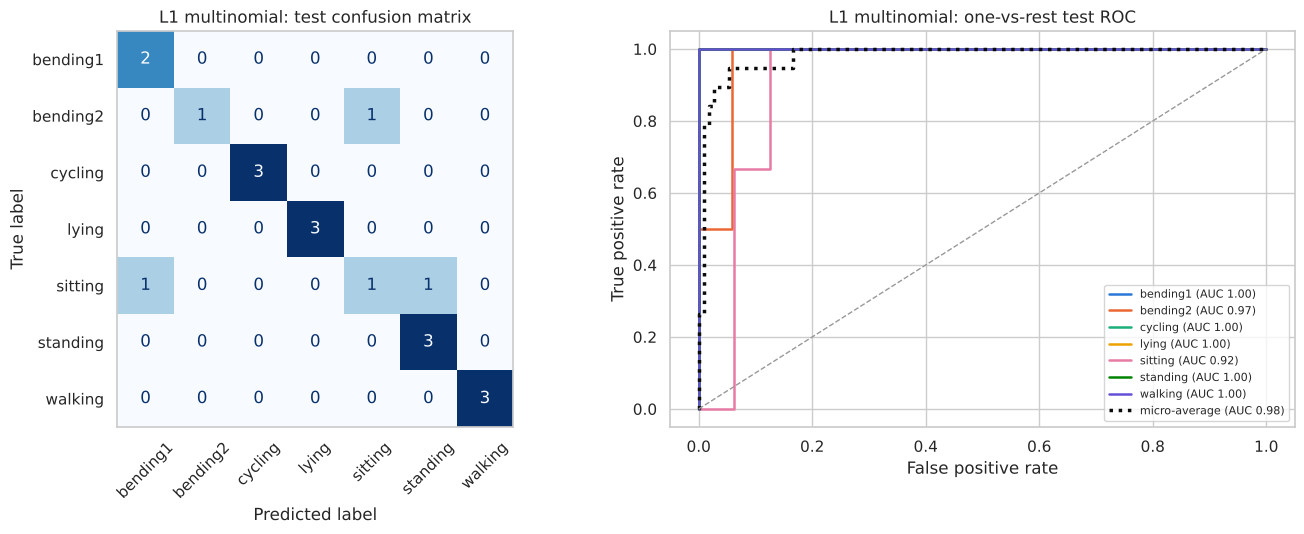

L1 multinomial: test accuracy = 0.8421, test error = 0.1579
micro-average AUC = 0.9815, macro-average AUC = 0.9839
Features with a nonzero coefficient in at least one class: 83 of 84


In [ ]:
def multiclass_report(model, l, title):
    Xtr, ytr, Xte, yte = get_split(l, binary=False)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)
    classes = list(model.classes_)
    acc = accuracy_score(yte, pred)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    plot_confusion(yte, pred, classes, f"{title}: test confusion matrix", axes[0])
    axes[0].tick_params(axis="x", rotation=45)
    # One-vs-rest ROC: class k vs. all others, scored by P(class k | x); plus micro-average.
    Y = label_binarize(yte, classes=classes)
    aucs = {}
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        aucs[c] = auc(fpr, tpr)
        axes[1].plot(fpr, tpr, color=PALETTE[k], lw=1.8, label=f"{c} (AUC {aucs[c]:.2f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), proba.ravel())
    aucs["micro-average"] = auc(fpr, tpr)
    aucs["macro-average"] = np.mean([aucs[c] for c in classes])
    axes[1].plot(fpr, tpr, color="#0b0b0b", lw=2.5, ls=":", label=f"micro-average (AUC {aucs['micro-average']:.2f})")
    axes[1].plot([0, 1], [0, 1], ls="--", color="#999999", lw=1)
    axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
    axes[1].set_title(f"{title}: one-vs-rest test ROC"); axes[1].legend(fontsize=8, loc="lower right")
    plt.tight_layout(); plt.show()
    print(f"{title}: test accuracy = {acc:.4f}, test error = {1 - acc:.4f}")
    print(f"micro-average AUC = {aucs['micro-average']:.4f}, macro-average AUC = {aucs['macro-average']:.4f}")
    return {"acc": acc, "err": 1 - acc, "micro": aucs["micro-average"], "macro": aucs["macro-average"],
            "pred": pred, "y": yte}
model_c = make_pipeline(StandardScaler(), logreg("l1", C=C_C, solver="saga", max_iter=1000, tol=1e-3))
res_c = multiclass_report(model_c, L_C, "L1 multinomial")
nz = (model_c[-1].coef_ != 0).any(axis=0).sum()
print(f"Features with a nonzero coefficient in at least one class: {nz} of {model_c[-1].coef_.shape[1]}")

**Result (2(c)i).**

Best pair: **$l = 2$, $C = 31.6$**, 5-fold CV accuracy 0.9286.

* The heatmap shows us that if $C$ is less than or equal to $0.032$, then all coefficients will equal zero, and the model's accuracy will range from $0.15$ to $0.17$. At this point, the model only predicts one class for every data point. However, as $C$ increases, the model's accuracy improves significantly. The heatmap also indicates that small values of $l$ ($1$ or $2$) provide the best results.In contrast to the binary problem, where the value of $l$ made little difference, larger $l$ values clearly decrease the model’s performance in the multiclass problem., larger $l$ values clearly decrease the model's performance in the multiclass problem. This could be due to the fact that the seven-class problem has only $4$ to $12$ examples available for each class during training. Thus, the $42l$ features are more likely to lead to overfitting than in the binary problem.

* Test error = 0.158 (16/19 correct, accuracy 0.842). Errors: bending2/dataset2 predicted sitting, sitting/dataset1 predicted standing, sitting/dataset3 predicted bending1. Every cycling, lying, standing, walking, and bending1 test example is classified correctly. All errors were made within the less-active classes, and bending2 only contained 4 training examples.

* The penalty is small at $C=31.6$: 83 of the 84 variables had a non-zero coefficient for at least one class. Therefore, CV selected a mostly un-penalized multinomial model versus a sparse model.

**Multiclass confusion matrix and ROC**.

* The confusion matrix is now a $K \times K$ table (in this case, $7 \times 7$); each cell $(i, j)$ represents the number of times that a test instance of true class $i$ was predicted as class $j$. All cells along the main diagonal are correct predictions.

* The most common way to extend ROC curves, which are based on a binary score, is one-vs-rest. For each of the seven classes (one at a time), we treat "class $k$" as positive and all other classes as negative. We then use the predicted probability of an instance belonging to class $k$ as our score. This produces an ROC curve and AUC for each class. To combine these curves and AUCs into a single measure, there are two summary measures: Micro-averaging, which combines the $K$ binary classification problems into a single problem (where each instance-class combination is treated equally) and creates a single ROC curve; Macro-averaging, which is simply the average of the AUC values from each individual class.

* Micro-averaged AUC is 0.9815; Macro-averaged AUC is 0.9839. Every single class has an AUC of 1.00 with the exception of 'bending2' (0.97) and 'sitting' (0.92) as these were the two classes that had errors.

### 2(c)ii. Naive Bayes with Gaussian and multinomial likelihoods

The only tuning parameter is $l$, chosen by the same stratified 5-fold CV (ties to smaller $l$).

* **Gaussian NB** models each feature within each class as a normal distribution with its own mean and variance; it needs no scaling.
* **Multinomial NB** models nonnegative count-like features. Our features are continuous, so I map each feature to $[0, 1]$ with a `MinMaxScaler` fit inside each fold, and treat the scaled values as fractional counts. Test values outside the training range are clipped to $[0, 1]$ so that no input is negative.

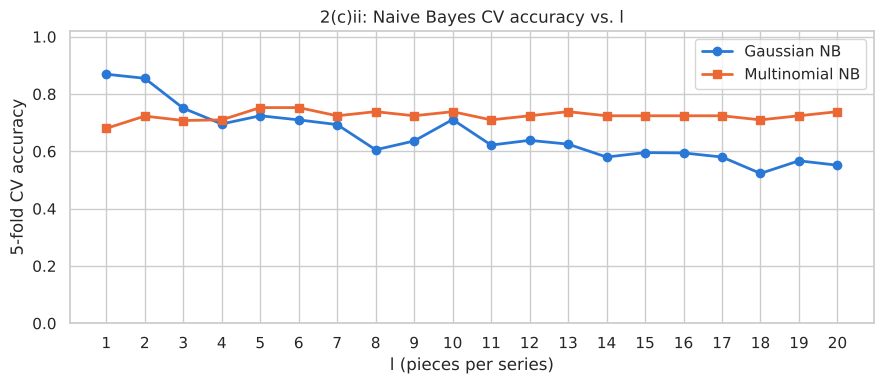

Gaussian NB best l = 1 (CV acc 0.8692);  Multinomial NB best l = 5 (CV acc 0.7527)


In [ ]:
def nb_cv(make_model):
    rows = []
    for l in range(1, 21):
        Xtr, ytr, _, _ = get_split(l, binary=False)
        X = Xtr.to_numpy()
        accs = [accuracy_score(ytr[b], make_model().fit(X[a], ytr[a]).predict(X[b])) for a, b in skf.split(X, ytr)]
        rows.append({"l": l, "cv_acc": np.mean(accs)})
    return pd.DataFrame(rows)
make_gnb = lambda: GaussianNB()
make_mnb = lambda: make_pipeline(MinMaxScaler(clip=True), MultinomialNB())
cv_gnb, cv_mnb = nb_cv(make_gnb), nb_cv(make_mnb)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cv_gnb.l, cv_gnb.cv_acc, "o-", color=PALETTE[0], lw=2, ms=6, label="Gaussian NB")
ax.plot(cv_mnb.l, cv_mnb.cv_acc, "s-", color=PALETTE[1], lw=2, ms=6, label="Multinomial NB")
ax.set_xticks(range(1, 21)); ax.set_ylim(0, 1.02)
ax.set_xlabel("l (pieces per series)"); ax.set_ylabel("5-fold CV accuracy")
ax.set_title("2(c)ii: Naive Bayes CV accuracy vs. l"); ax.legend()
plt.tight_layout(); plt.show()
L_G = int(cv_gnb.sort_values(["cv_acc", "l"], ascending=[False, True]).iloc[0].l)
L_M = int(cv_mnb.sort_values(["cv_acc", "l"], ascending=[False, True]).iloc[0].l)
print(f"Gaussian NB best l = {L_G} (CV acc {cv_gnb.cv_acc.max():.4f});  "
      f"Multinomial NB best l = {L_M} (CV acc {cv_mnb.cv_acc.max():.4f})")

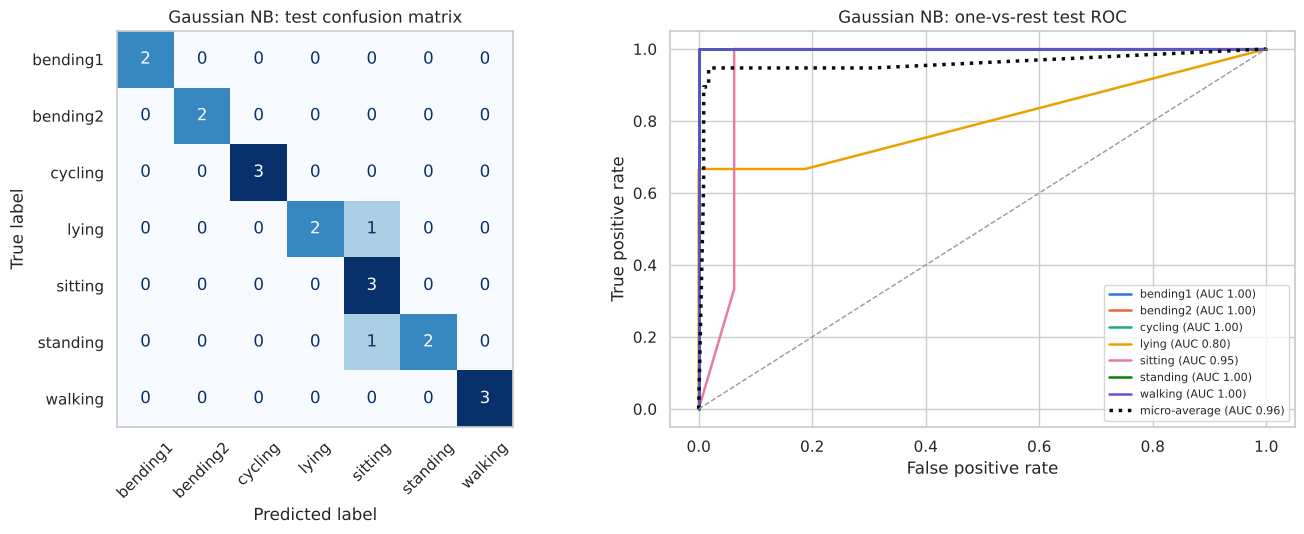

Gaussian NB: test accuracy = 0.8947, test error = 0.1053
micro-average AUC = 0.9596, macro-average AUC = 0.9643


In [ ]:
res_g = multiclass_report(make_gnb(), L_G, "Gaussian NB")

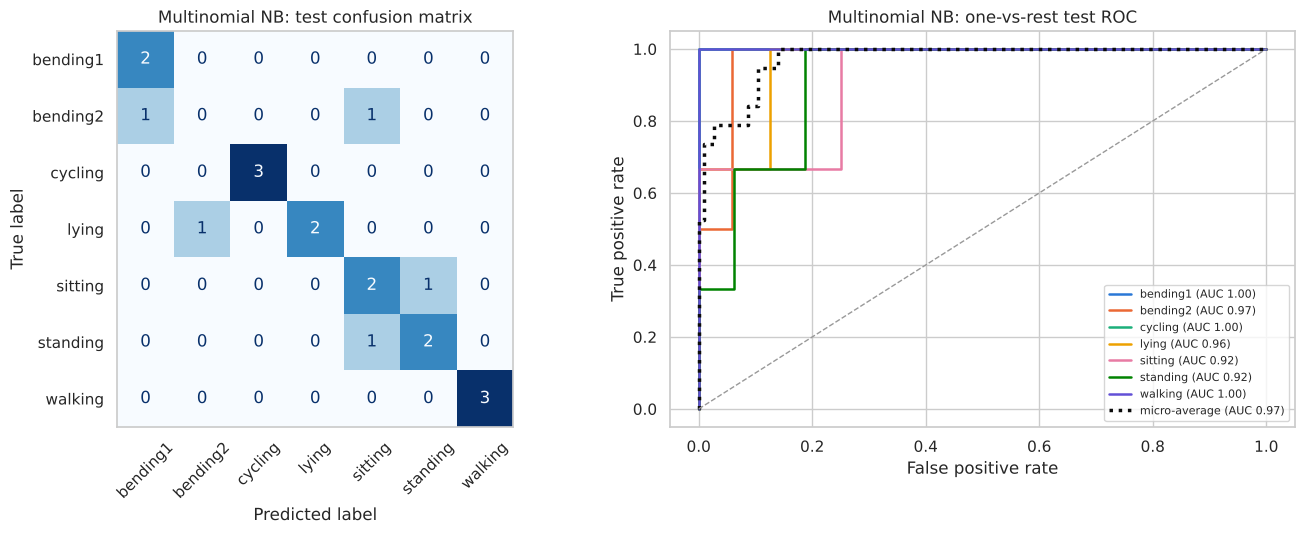

Multinomial NB: test accuracy = 0.7368, test error = 0.2632
micro-average AUC = 0.9737, macro-average AUC = 0.9660


In [ ]:
res_m = multiclass_report(make_mnb(), L_M, "Multinomial NB")

**Result (2(c)ii).**

| | chosen $l$ | CV accuracy | test accuracy | test error | micro AUC |
|---|---|---|---|---|---|
| Gaussian NB | 1 | 0.869 | 0.895 (17/19) | 0.105 | 0.960 |
| Multinomial NB | 5 | 0.753 | 0.737 (14/19) | 0.263 | 0.974 |

* **Gaussian Naive Bayes** misclassified the lying/dataset2 and standing/dataset1 data sets, classifying each one as sitting.

* **The multinomial naive bayes** classifier makes five errors. All of these errors occurred in the lower-movement classes. Two of the bending2 test cases were misclassified: one as bending1 and the other as sitting. One of the lying test cases was classified as bending2. The classifications for sitting and standing were switched once each.

* The Gaussian model was by far the best of the Naive Bayes models with respect to CV accuracy (0.87 vs 0.75), and testing performance (17 vs 14 correct). This was to be expected as the features used in this analysis were continuously measured and therefore, could be modeled reasonably well using a per-class normal density. Multinomial likelihood is designed to model counts. When features are min-max scaled, multinomial likelihood essentially scores how the feature values for each observation are distributed proportionally across columns. In doing so, it discards information about the absolute value of each feature; however, the absolute value of features (such as the variance levels that differentiate cycling and walking from the low-movement activities) is precisely what is important in this case.

* One surprising fact about this model: Multinomial NB has a higher AUC value than Gaussian NB (micro-average AUC 0.97 vs. 0.96), even though it has a lower overall classification rate (accuracy). The reason for this is that Gaussian NB takes into account 42 features that have strong correlations with each other, but treats them as if they are independent. This results in the same piece of "evidence" being counted twice and therefore the probabilities that Gaussian NB produces will be extremely overconfident. Therefore, if the model misclassifies an observation, it will be very confident in that misclassification; for example, the lying observation that was misclassified as something else will have a very low lying probability associated with it. This lowers the AUC for the lying one-vs-rest model to 0.80.

### 2(c)iii. Which method is better for multi-class classification here?

In [ ]:
summary_c = pd.DataFrame({
    "chosen l": [L_C, L_G, L_M],
    "5-fold CV accuracy": [best_m.cv_acc, cv_gnb.cv_acc.max(), cv_mnb.cv_acc.max()],
    "test accuracy": [res_c["acc"], res_g["acc"], res_m["acc"]],
    "test error": [res_c["err"], res_g["err"], res_m["err"]],
    "micro AUC": [res_c["micro"], res_g["micro"], res_m["micro"]],
    "macro AUC": [res_c["macro"], res_g["macro"], res_m["macro"]],
}, index=["L1 multinomial logistic", "Gaussian NB", "Multinomial NB"])
display(summary_c.style.format("{:.4f}", subset=summary_c.columns[1:]))

,chosen l,5-fold CV accuracy,test accuracy,test error,micro AUC,macro AUC
L1 multinomial logistic,2,0.9286,0.8421,0.1579,0.9815,0.9839
Gaussian NB,1,0.8692,0.8947,0.1053,0.9596,0.9643
Multinomial NB,5,0.7527,0.7368,0.2632,0.9737,0.9660


**Answer (2(c)iii):** The L1-penalized multinomial logistic regression was found to be the best model, followed by the Gaussian Naive Bayes model which was a close second and the Multinomial Naive Bayes model as the least effective.

Cross Validation (69 examples), the method employed to select the most appropriate model: L1 multinomial model with an accuracy of 0.929 was superior to the Gaussian Naive Bayes model with an accuracy of 0.869 which was superior to the Multinomial Naive Bayes model with an accuracy of 0.753. There are approximately four training examples separating the first two models.

On the test set (19 instances), Gaussian NB classified 17 of 19 correctly, the L1 multinomial model 16 of 19, and the Multinomial NB model 14 of 19. The difference between the top-performing models was one instance. One instance out of 19 is well within the noise of a 19-instance test set. Furthermore, 3 of the test instances are duplicates of training instances.

Probability quality: The L1 multinomial model has the highest micro and macro AUC (0.98), and therefore does the best job of ranking the classes. The Gaussian Naive Bayes' assumption of independence results in overconfidence when making probability estimates.

I am choosing the L1 multinomial model because its advantage in cross-validation, which uses more data, and its better probability estimates outweigh a one-instance difference on the test set. The Gaussian NB method continues to be a viable alternative due to being a rapid, non-tuned baseline model that is close in performance. A common limitation among each of the three models is that they struggle to classify the low movement classes (sitting, standing, lying, and bending2 with only four training examples) whereas the models consistently identify the classification of cycling and walking correctly.

## ISLR 4.8.3: A Bayes classifier is a quadratic classifier when the classes have different variances (with p=1).
Setting Up: You have one predictor and $K$ different types of categories or "classes." Each category/class has a variable $X$ that follows a Normal Distribution with a mean of $\mu_k$ and a variance of $\sigma_k^2$:
$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$
$k$ prior probability is $\pi_k$. Variances in the classification of $k$ are not assumed to be equal like they would be in LDA.
Bayes classifier. Using Bayes' theorem,
$$
P(Y=k\mid X=x)=
\frac{\pi_k f_k(x)}
{\sum_{l=1}^{K}\pi_l f_l(x)}.
$$
We can select the class which has the highest value of $\pi_k f_k(x)$, as the denominator will remain the same for each of the classes.

Taking the logarithm and ignoring constants, we get
$$
\delta_k(x)=\log(\pi_k)-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$
Expanding the square,
$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_kx}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k).
$$
Proof. Since the variance in data for each class is different from that in other classes, the value of the coefficient of $x^2$ will be different for each class. As a result, when we compare two classes, the quadratic terms will not cancel out; consequently, the decision boundary between the two classes will be quadratic.

LDA assumes that all classes have identical variances. Thus, the quadratic terms will be eliminated, and the decision boundary will be linear. Therefore, if the classes have different variances, the Bayes classifier will be quadratic.

## ISLR 4.8.7: Probability that a company issues a dividend when $X=4$
Given. Companies issuing dividends (Yes) have a mean of 10, while companies not issuing dividends (No) have a mean of 0. Both groups have a common variance of 36, and 80 percent of companies issue dividends.
Therefore,
$$
P(\text{Yes})=0.8,\qquad P(\text{No})=0.2.
$$
Using Bayes' theorem,
$$
P(\text{Yes}\mid X=4)=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$
The common normal density factor is eliminated because both classes have the same variance. Therefore,
$$
P(\text{Yes}\mid X=4)=
\frac{0.8e^{-(4-10)^2/72}}
{0.8e^{-(4-10)^2/72}+0.2e^{-(4-0)^2/72}}.
$$
Calculating the exponential terms,
$$
e^{-36/72}\approx 0.60653
$$
$$
e^{-16/72}\approx 0.80074.
$$
Substituting these values,
$$
P(\text{Yes}\mid X=4)=
\frac{0.8(0.60653)}
{0.8(0.60653)+0.2(0.80074)}
$$
$$
=\frac{0.48522}{0.64537}
\approx 0.752.
$$
Answer: When the value of X is 4, there is a probability of approximately 75.2% that a company will issue dividends.